# Component 1: is the diet log reflected in the food-sequencing data? (LONGIT-weeklong)

Food DNA in stool, capsule and saliva samples was sequenced with two markers: **trnL** (plants run) and **12SV5** (meat run,
vertebrates). This notebook compares what each subject logged with what was detected. The workflow is in
`diet_log_analyses/CLAUDE.md`; reusable code is in `scripts/diet_log.py` and `scripts/food_seq.py` (both tested in
`scripts/tests/test_modules.py` against the earlier outputs).

**Terms used throughout**
- **Recall:** of the times a food was eaten (in the time window considered), the share in which its DNA was detected.
- **Precision:** of the times a food's DNA was detected, the share in which the food had been eaten.

**Sections**
- **0. Diet log next to food sequencing** (descriptive; nothing is tested).
- **1. Analysis plan** (to be drafted next).

Figures are shown here and saved to `figures/component1_foodseq_diet/` as PNG (300 dpi) and PDF, each with the CSV it was drawn from.

## Parameters
Everything that can change a result is set here, once.

In [1]:
import sys
from pathlib import Path

# make diet_log_analyses/scripts importable when the notebook is run from another folder
here = Path.cwd()
scripts = next(p for p in [here, here / "diet_log_analyses" / "scripts", here / "scripts"] if (p / "_paths.py").exists())
sys.path.insert(0, str(scripts))

import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import _paths            # paths: FIG_DIR, DIET_CODING; also puts 2-analysis_python on sys.path
import config as C       # shared helpers (read_excel_like_readxl, ...)
import diet_log as DL    # diet-log tables, meal assignment
import food_seq as FS    # food-sequencing tables, ingredient -> ASV matching
import weeklong_16s as W # read_sample_sheet()

FIG_FOLDER = "component1_foodseq_diet"   # all figures of this notebook go to figures/<FIG_FOLDER>/
TOP_N_TAXA = 25          # food taxa shown in the figures (most often eaten)
DETECT_MIN = 0.001       # a food taxon is "detected" when its ASVs make up >= 0.1% of a library's reads
DETECT_SENS = (0.01, 0.05)   # stricter detection thresholds for section 0.10 (1% planned sensitivity; 5% exploratory)
# section 0.12, sensitivity rules for detection
MIN_TAXON_READS = 10     # rule 1: also require at least this many reads of the food taxon
RARE_DEPTH = 2000        # rule 2: every library subsampled to this many reads (libraries with fewer are left out)
RARE_MIN = 2             # rule 2: detected when >= this many of the subsampled reads (2 of 2,000 = 0.1%)
RARE_SEED = 20261019     # rule 2: fixed seed for the subsampling
BLANK_QUANTILE = 0.95    # rule 3: share must exceed this quantile of the taxon's share in the run's blanks
MIN_READS = 500          # food-run libraries with fewer reads are excluded (for that run)
SAMPLE_TYPES = {"Stool": "Stool", "Capsule": "Capscan", "Saliva": "Saliva"}   # label -> Sample_origin3

def pct(thr):
    return f"{thr * 100:g}%"                          # 0.001 -> "0.1%"

def cutoffs(thr=DETECT_MIN):
    # the two cut-offs, written on every figure that uses sequenced samples
    return (f"Cut-offs: samples with >= {MIN_READS} reads in the food run; a food is detected when its ASVs make up "
            f">= {pct(thr)} of the sample's reads.")

# config.py switches matplotlib to a non-display backend; show figures inline in the notebook again
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})
print("figures will be saved to:", _paths.FIG_DIR / FIG_FOLDER)

figures will be saved to: /Users/lisa/Documents/GitHub/gen2-longit/diet_log_analyses/figures/component1_foodseq_diet


## Input versions (workflow steps 0 and 2)
Each input's checksum is recomputed and compared with `figures/input_profiles/manifest.json` (written by
`scripts/profile_inputs.py`). **Expected:** all match. A mismatch means an input changed since it was last profiled: rerun
the profiler and the tests before trusting anything below.

In [2]:
manifest = json.loads((_paths.FIG_DIR / "input_profiles" / "manifest.json").read_text())
for name in ["daily_diet_coding", "sample_sheet", "food_sample_info", "plants_seqtab_all", "meat_seqtab_all",
             "plants_feature_data", "meat_feature_data"]:
    entry = manifest[name]
    sha = hashlib.sha256(Path(entry["path"]).read_bytes()).hexdigest()
    print(f"{name:20s} modified {entry['modified']}  {'MATCH' if sha == entry['sha256'] else 'MISMATCH: rerun profile_inputs.py and the tests'}")

daily_diet_coding    modified 2026-10-18T21:00:48  MATCH
sample_sheet         modified 2026-10-17T11:12:25  MATCH
food_sample_info     modified 2026-10-09T14:07:24  MATCH
plants_seqtab_all    modified 2026-10-09T14:07:24  MATCH
meat_seqtab_all      modified 2026-10-09T14:07:24  MATCH
plants_feature_data  modified 2026-10-09T14:07:24  MATCH
meat_feature_data    modified 2026-10-09T14:07:24  MATCH


# 0. Diet log next to food sequencing

A first, descriptive look: for the most often eaten foods, on which days (and at which meal) each subject logged them, and
on which days their DNA was detected in a stool, capsule or saliva sample. Nothing is tested here.

### 0.1 Diet log and meals
`DL.load()` reads the coded diet log; `DL.assign_meals()` gives each food entry a meal (Breakfast, Lunch, Dinner, or
"not recorded"), using the rule in CLAUDE.md (meal word first, else clock time).
**Expected:** 1,461 entries, 167 subject-days, 19 subjects; meal labels only from the four allowed values.

In [3]:
entries, lexicon, mentions = DL.load()
meals = DL.assign_meals(entries)
mentions = mentions.merge(meals, on=["Day_key", "Entry_no"], how="left")
print(f"food entries: {len(entries):,}; subject-days: {entries[['subject', 'date']].drop_duplicates().shape[0]}; "
      f"subjects: {entries.subject.nunique()}")
print("entries per meal:", meals.meal.value_counts().reindex(DL.MEALS).to_dict())
print(f"ingredient mentions without a meal label: {int(mentions.meal.isna().sum())}")
log_days = entries.groupby("subject")["date"].agg(first="min", last="max")

food entries: 1,461; subject-days: 167; subjects: 19
entries per meal: {'Breakfast': 150, 'Lunch': 156, 'Dinner': 212, 'not recorded': 943}
ingredient mentions without a meal label: 0


### 0.2 Food taxa: what the sequencing can tell apart
Each ingredient rated `Informative for sequencing? = Yes` is matched to its **compatible ASVs** in the run its marker
belongs to (trnL → plants, 12SV5 → meat), by the rule in CLAUDE.md. Ingredients whose ASVs overlap cannot be told apart by
sequencing, so they are merged into one **food taxon**, labelled by what the sequencing reports (e.g. *Bos taurus* = cow milk,
cheese, beef, ...). Matching is done for each species an ingredient lists, so a recipe such as kimchi (cabbage, radish,
garlic, ginger, chili) counts towards each of those taxa without merging them into one.
**Expected:** milk, cheese and beef in one taxon labelled *Bos taurus*; no ASV in two taxa; cabbage and garlic in
different taxa (all tested in `tests/test_modules.py`).

In [4]:
runs = FS.load_runs()
taxa, member = FS.food_taxa(lexicon, runs)
print(f"informative ingredients with compatible ASVs: {len(member)} (in more than one taxon: {sum(len(v) > 1 for v in member.values())}); "
      f"merged into {len(taxa)} food taxa "
      f"(plants {int((taxa.run == 'plants').sum())}, meat {int((taxa.run == 'meat').sum())})")

# how often each taxon was eaten: subject-days on which any of its ingredients was logged
# an ingredient can belong to several taxa (a recipe such as kimchi lists several species): one row per taxon
mt = mentions.assign(taxon_id=mentions.ingredient.map(member)).dropna(subset=["taxon_id"]).explode("taxon_id")
eaten_days = mt.groupby("taxon_id").apply(lambda g: g[["subject", "date"]].drop_duplicates().shape[0], include_groups=False)
taxa["subject_days_eaten"] = taxa.taxon_id.map(eaten_days).fillna(0).astype(int)
taxa = taxa.sort_values(["subject_days_eaten", "label"], ascending=[False, True]).reset_index(drop=True)
top = taxa.head(TOP_N_TAXA).copy()
top["row_label"] = [f"{l} ({'trnL' if r == 'plants' else '12SV5'})" for l, r in zip(top.label, top.run)]
pd.set_option("display.max_colwidth", 70)
print(f"Top {TOP_N_TAXA} food taxa by subject-days eaten (of 167):")
print(top[["row_label", "subject_days_eaten", "n_asvs", "ingredients"]].to_string(index=False))
top.drop(columns="asvs").to_csv(_paths.FIG_DIR / FIG_FOLDER / "00_top_food_taxa.csv", index=False) if (_paths.FIG_DIR / FIG_FOLDER).exists() else None

informative ingredients with compatible ASVs: 116 (in more than one taxon: 2); merged into 68 food taxa (plants 55, meat 13)
Top 25 food taxa by subject-days eaten (of 167):
                row_label  subject_days_eaten  n_asvs                                                                                                    ingredients
       Bos taurus (12SV5)                 133     139                                   beef, cheese, cow milk, cream, cream cheese, ice cream, paneer, veal, yogurt
 Triticum aestivum (trnL)                 132     132                                                                                                          wheat
      Oryza sativa (trnL)                 114     101                                                                                           glutinous rice, rice
      Solanum spp. (trnL)                  94      16                                                                                       eggplant, potato, tomato
 

### 0.2b Naming check: do the lexicon's scientific names find the sequences?
For every logged ingredient rated informative, how its lexicon species name matches the ASVs of its run, **species first,
then genus** (CLAUDE.md, "Ingredients to taxa"):
- **exact species:** ASVs labelled with the same species (plants: the epithet, e.g. `max`; meat: the binomial, e.g. `Bos taurus`);
- **genus, unlabelled:** ASVs of the same genus with no species label (sequencing could not decide the species);
- **genus, congener fallback:** no ASV in the run carries the food's own species, so all ASVs of the genus count (e.g. every
  *Spinacia* ASV is labelled *S. tetrandra*); the labels the run uses are listed so a naming mistake would be visible;
- **genus not in run:** the genus does not occur among the run's ASVs at all: either the food left no detectable DNA, or the
  lexicon name does not match the reference taxonomy (a spelling or synonym problem worth checking);
- **no taxon:** the lexicon entry has no genus to match (e.g. "unspecified fruit", slash lists).
Reads = all reads of the compatible ASVs across all libraries of the run (study samples and blanks), to show whether the
match points at sequences that are actually present. **Expected:** most whole foods match at species or genus level.

In [5]:
inf = lexicon[(lexicon["Informative for sequencing? (Yes / Uncertain / No)"] == "Yes") & lexicon.Ingredient.isin(set(mentions.ingredient))]
asv_reads = {run: counts.sum(axis=0) for run, (counts, _) in runs.items()}
STATUS = ["exact species", "genus, unlabelled only", "genus, congener fallback", "whole genus (no single species named)",
          "genus not in run", "no taxon"]
check_rows = []
for r in inf.itertuples(index=False):
    marker = r[inf.columns.get_loc("Marker that can detect it")]
    run = FS.RUN_OF_MARKER.get(marker)
    if run is None:
        continue
    field = r[inf.columns.get_loc(FS.SPECIES)]
    d = FS.match_detail(field, runs[run][1], run)
    asvs = FS.compatible_asvs(field, runs[run][1], run)
    # bar segments per species part: exact species; unlabelled ASVs of the genus; congener fallback (whole genus because
    # the food's species is never assigned); whole genus because no single species is named (spp., hybrid)
    has_epi = d.epithet.notna()
    seg_exact = int(d.exact[has_epi & ~d.fallback].sum())
    seg_unl = int(d.unlabelled[has_epi & ~d.fallback].sum())
    seg_fb = int(d.compatible[d.fallback].sum())
    seg_whole = int(d.compatible[~has_epi].sum())
    status = ("exact species" if seg_exact else "genus, congener fallback" if seg_fb
              else "whole genus (no single species named)" if seg_whole else "genus, unlabelled only" if seg_unl
              else "genus not in run" if d.genus.notna().any() else "no taxon")
    check_rows.append({"ingredient": r.Ingredient, "run": run, "lexicon species": field, "status": status,
                       "exact": seg_exact, "unlabelled": seg_unl, "fallback": seg_fb, "whole_genus": seg_whole,
                       "compatible": len(asvs),
                       "reads": int(asv_reads[run].reindex(list(asvs)).fillna(0).sum()),
                       "run labels for the genus": "; ".join(x for x in d.run_labels if x),
                       "food taxon": ", ".join(LBL for LBL in (taxa.set_index("taxon_id").label.get(t, "") for t in member.get(r.Ingredient, [])))})
naming = pd.DataFrame(check_rows)
seg_sum = naming[["exact", "unlabelled", "fallback", "whole_genus"]].sum(axis=1)
print(f"check: bar segments add up to the matched ASVs for {int((seg_sum == naming.compatible).sum())} of {len(naming)} ingredients "
      f"(others: species parts share ASVs: {', '.join(naming.ingredient[seg_sum != naming.compatible]) or 'none'})")
print("ingredients checked:", len(naming), "| by status:")
print(naming.groupby(["run", "status"]).size().unstack(fill_value=0).reindex(columns=STATUS, fill_value=0).to_string())
print()
print("not matched (genus not in run / no taxon):")
print(naming[naming.status.isin(["genus not in run", "no taxon"])][["run", "ingredient", "lexicon species", "status"]].to_string(index=False))
print()
print("congener fallback (check the labels the run uses):")
print(naming[naming.status == "genus, congener fallback"][["run", "ingredient", "lexicon species", "run labels for the genus"]].to_string(index=False))

check: bar segments add up to the matched ASVs for 141 of 142 ingredients (others: species parts share ASVs: kimchi)
ingredients checked: 142 | by status:
status  exact species  genus, unlabelled only  genus, congener fallback  whole genus (no single species named)  genus not in run  no taxon
run                                                                                                                                       
meat               17                       2                         1                                      2                 1         1
plants             47                      13                        26                                      8                24         0

not matched (genus not in run / no taxon):
   run       ingredient                            lexicon species           status
plants             acai                           Euterpe oleracea genus not in run
plants            apple                            Malus domestica genus not 

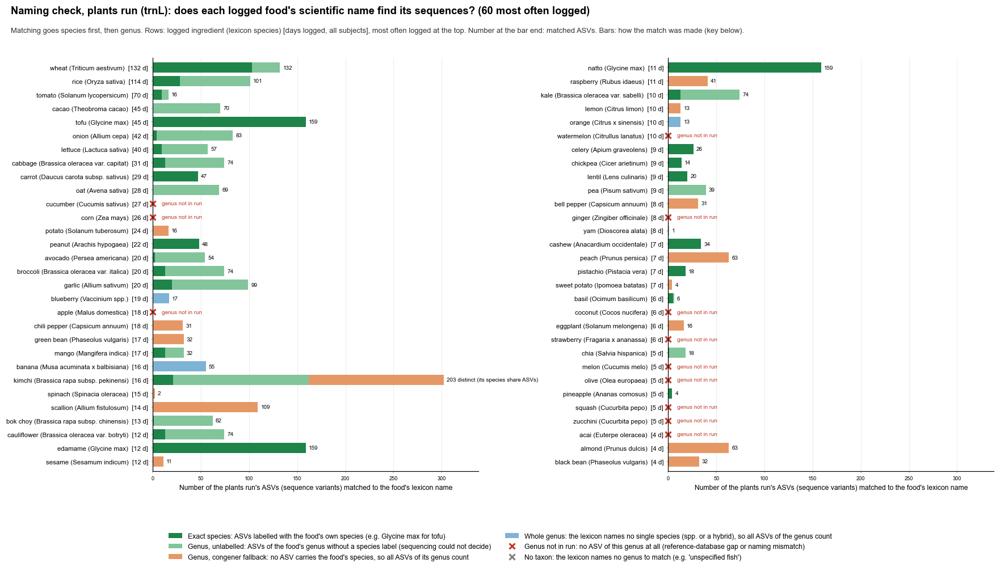

saved (slide version, 60 most logged): 02_naming_check_plants.png, 02_naming_check_plants.pdf, 02_naming_check_plants.csv


saved (all plant ingredients): 02_naming_check_plants_all.png, 02_naming_check_plants_all.pdf, 02_naming_check_plants_all.csv


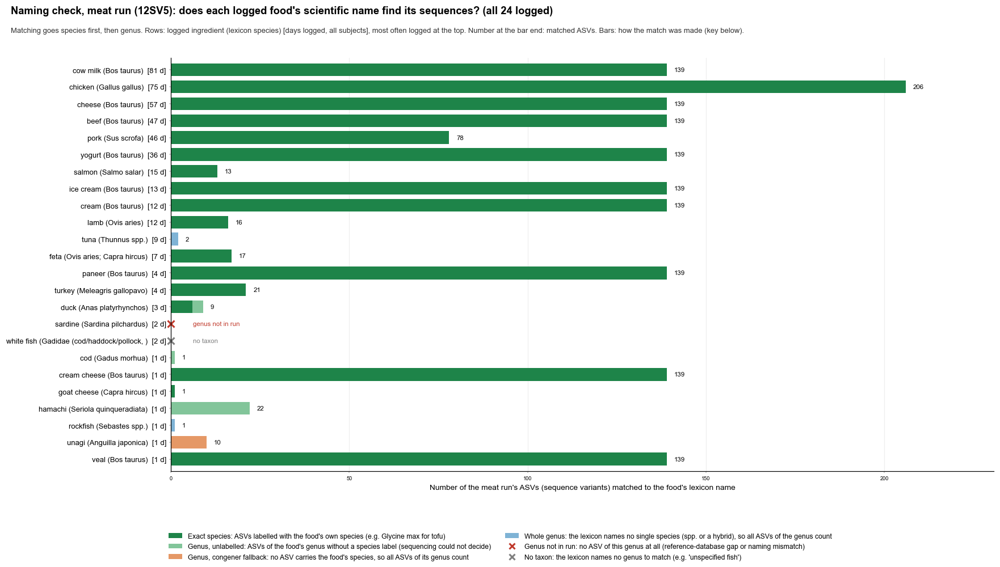

saved: 02_naming_check_meat.png, 02_naming_check_meat.pdf, 02_naming_check_meat.csv


In [6]:
STATUS_COLORS = {"exact species": "#1E8449", "genus, unlabelled only": "#82C59A", "genus, congener fallback": "#E59866",
                 "whole genus (no single species named)": "#7FB3D5", "genus not in run": "#C0392B", "no taxon": "#7F7F7F"}
# days each ingredient was logged (subject-days), used to pick and sort the ingredients shown
logged_days = mentions.groupby("ingredient").apply(lambda g: g[["subject", "date"]].drop_duplicates().shape[0], include_groups=False)
naming["days_logged"] = naming.ingredient.map(logged_days).fillna(0).astype(int)

KEY = [Patch(facecolor=STATUS_COLORS["exact species"],
             label="Exact species: ASVs labelled with the food's own species (e.g. Glycine max for tofu)"),
       Patch(facecolor=STATUS_COLORS["genus, unlabelled only"],
             label="Genus, unlabelled: ASVs of the food's genus without a species label (sequencing could not decide)"),
       Patch(facecolor=STATUS_COLORS["genus, congener fallback"],
             label="Genus, congener fallback: no ASV carries the food's species, so all ASVs of its genus count"),
       Patch(facecolor=STATUS_COLORS["whole genus (no single species named)"],
             label="Whole genus: the lexicon names no single species (spp. or a hybrid), so all ASVs of the genus count"),
       Line2D([], [], marker="x", ls="", color=STATUS_COLORS["genus not in run"], mew=2,
              label="Genus not in run: no ASV of this genus at all (reference-database gap or naming mismatch)"),
       Line2D([], [], marker="x", ls="", color=STATUS_COLORS["no taxon"], mew=2,
              label="No taxon: the lexicon names no genus to match (e.g. 'unspecified fish')")]

def draw_naming(ax, d, fontsize, xmax):
    # one row per ingredient, most often logged at the top; stacked bar = the ASVs its lexicon name matched
    d = d.reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    ax.barh(y, d.exact, color=STATUS_COLORS["exact species"], height=0.75)
    ax.barh(y, d.unlabelled, left=d.exact, color=STATUS_COLORS["genus, unlabelled only"], height=0.75)
    ax.barh(y, d.fallback, left=d.exact + d.unlabelled, color=STATUS_COLORS["genus, congener fallback"], height=0.75)
    ax.barh(y, d.whole_genus, left=d.exact + d.unlabelled + d.fallback,
            color=STATUS_COLORS["whole genus (no single species named)"], height=0.75)
    for yi, r in zip(y, d.itertuples(index=False)):
        if r.compatible == 0:
            ax.plot(0, yi, "x", color=STATUS_COLORS[r.status], mew=2, ms=fontsize - 1, clip_on=False)
            ax.text(xmax * 0.03, yi, r.status, va="center", fontsize=fontsize - 1, color=STATUS_COLORS[r.status])
        else:
            end = r.exact + r.unlabelled + r.fallback + r.whole_genus      # equals r.compatible unless parts overlap
            ax.text(end + xmax * 0.01, yi, f"{r.compatible}" + ("" if end == r.compatible else " distinct (its species share ASVs)"), va="center",
                    fontsize=fontsize - 1)
    ax.set_yticks(y, [f"{a} ({b[:30]})  [{n} d]" for a, b, n in zip(d.ingredient, d["lexicon species"], d.days_logged)],
                  fontsize=fontsize)
    ax.set_xlim(0, xmax * 1.12)
    ax.set_ylim(-0.7, len(d) - 0.3)
    ax.grid(axis="x", color="#EEEEEE"); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

def naming_figure(d, run, marker, ncol, title_extra, figsize, fontsize):
    xmax = max(1, d.compatible.max(), (d.exact + d.unlabelled + d.fallback + d.whole_genus).max())
    fig, axes = plt.subplots(1, ncol, figsize=figsize, squeeze=False)
    per = int(np.ceil(len(d) / ncol))
    for k, ax in enumerate(axes[0]):
        part = d.iloc[k * per:(k + 1) * per]
        draw_naming(ax, part, fontsize, xmax)
        ax.set_xlabel(f"Number of the {run} run's ASVs (sequence variants) matched to the food's lexicon name", fontsize=fontsize + 0.5)
    fig.suptitle(f"Naming check, {run} run ({marker}): does each logged food's scientific name find its sequences?{title_extra}",
                 x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=12)
    fig.text(0.01, 0.948, "Matching goes species first, then genus. Rows: logged ingredient (lexicon species) [days logged, all subjects], "
             "most often logged at the top. Number at the bar end: matched ASVs. Bars: how the match was made (key below).",
             ha="left", fontsize=8.5, color="#333333")
    fig.legend(handles=KEY, loc="lower center", ncol=2, frameon=False, fontsize=8, columnspacing=2)
    fig.tight_layout(rect=(0, 0.12, 1, 0.94))
    return fig

for run, marker in [("plants", "trnL"), ("meat", "12SV5")]:
    d = naming[naming.run == run].sort_values(["days_logged", "ingredient"], ascending=[False, True])
    if run == "plants":
        fig = naming_figure(d.head(60), run, marker, 2, " (60 most often logged)", (16, 9), 7.5)
        files = DL.save(fig, "02_naming_check_plants", d.head(60), FIG_FOLDER)
        plt.show()
        print("saved (slide version, 60 most logged):", ", ".join(f.name for f in files))
        fig = naming_figure(d, run, marker, 2, f" (all {len(d)} logged)", (16, 0.11 * len(d) + 2.5), 7)
        files = DL.save(fig, "02_naming_check_plants_all", d, FIG_FOLDER)
        plt.close(fig)                               # full list saved for reference; not repeated on screen
        print("saved (all plant ingredients):", ", ".join(f.name for f in files))
    else:
        fig = naming_figure(d, run, marker, 1, f" (all {len(d)} logged)", (16, 9), 8.5)
        files = DL.save(fig, "02_naming_check_meat", d, FIG_FOLDER)
        plt.show()
        print("saved:", ", ".join(f.name for f in files))

**How to read it:** one row per logged informative ingredient, with its lexicon species in brackets and the number of days
it was logged (all subjects together); the plants figure shows the 60 most often logged (all are in
`02_naming_check_plants_all`). The bar shows the
ASVs its name matched: dark green = labelled with the exact species, light green = unlabelled ASVs of the genus, orange =
the whole genus because the run never assigns the food's own species (the labels the run does use are printed; if they look
like a different spelling or a synonym of the lexicon name, the lexicon may need correcting). Rows with no bar matched
nothing: red = the genus is absent from the run (no DNA, or a naming mismatch), grey = the lexicon entry has no genus.
The read count shows whether the matched sequences are actually present in the data.

### 0.3 Sequenced samples
One library per sample and run. A library with fewer than `MIN_READS` (500) reads is excluded for that run, because a
0.1% threshold is meaningless with very few reads. Blanks (no sample) are summarised as a control: they should carry few reads.
**Expected:** every LONGIT library joins to the sample sheet; most libraries pass the read minimum.

In [7]:
_, samples = W.read_sample_sheet(C.SAMPLE_SHEET)
lib = FS.libraries(samples, runs, MIN_READS)
print(f"LONGIT libraries: {len(lib)}; not found in the sample sheet: {int(lib.Subject_ID.isna().sum())}")
lib = lib[lib.Subject_ID.isin(set(entries.subject))]          # diet-log subjects only (subject 11 has no log)
print(f"libraries of diet-log subjects: {len(lib)}; included (>= {MIN_READS} reads): {int(lib.included.sum())}")
print(lib.groupby(["run", "Sample_origin3"]).agg(libraries=("library", "size"), included=("included", "sum"),
                                                  median_reads=("reads", "median")).to_string())
info = C.read_excel_like_readxl(C.DATA_DIR / "Weeklong-meat-plants-sample-info.xlsx")
for run, (counts, _) in runs.items():
    bl = info[(info["group"] == FS.INFO_GROUP[run]) & (info["Group"] == "Blank")]["Sample"].str.replace("sample_", "", n=1)
    r = bl.map(counts.sum(axis=1)).fillna(0)
    print(f"{run} blanks: {len(r)}, median reads {int(r.median()):,} (study libraries: {int(lib[lib.run == run].reads.median()):,})")

LONGIT libraries: 1298; not found in the sample sheet: 0
libraries of diet-log subjects: 1218; included (>= 500 reads): 1182
                       libraries  included  median_reads
run    Sample_origin3                                   
meat   Capscan               321       295       57383.0
       Saliva                157       154       69534.0
       Stool                 131       131      111059.0
plants Capscan               321       315      102871.0
       Saliva                157       157      892013.0
       Stool                 131       130      111403.0


plants blanks: 105, median reads 84,377 (study libraries: 130,836)
meat blanks: 105, median reads 2,204 (study libraries: 70,804)


### 0.4 Detection in each sample
A food taxon is **detected** in a library when its compatible ASVs make up at least `DETECT_MIN` (0.1%) of that library's
reads. Only included libraries of the taxon's own run count. For capsules, the three regions (R1-R3) of one kit are combined:
the taxon counts as detected on that day if it is detected in any region. Samples are placed on their **collection date**
(saliva: the capsule ingestion time; CLAUDE.md).
**Expected:** one row per (subject, collection date, sample type, food taxon) for the included samples.

In [8]:
ab = FS.taxon_abundance(lib[lib.included], taxa, runs)   # all food taxa
ab = ab.merge(lib[["run", "library", "Sample_ID", "Subject_ID", "Sample_origin3", "Region", "Collection_date_reformat"]],
              on=["run", "library"])
ab["date"] = pd.to_datetime("2025-" + ab.Collection_date_reformat, errors="coerce")
print(f"libraries without a collection date (left out of the figures): {ab.drop_duplicates('library').date.isna().sum()}")
ab = ab.dropna(subset=["date"])
ab["detected"] = ab.rel >= DETECT_MIN
det = (ab.groupby(["Subject_ID", "date", "Sample_origin3", "taxon_id"])
         .agg(detected=("detected", "any"), max_rel=("rel", "max"), n_libraries=("library", "nunique")).reset_index())
print(f"rows (subject x date x sample type x taxon): {len(det):,}")
print("share of rows detected, by sample type:", det.groupby("Sample_origin3").detected.mean().round(3).to_dict())

libraries without a collection date (left out of the figures): 22
rows (subject x date x sample type x taxon): 24,739
share of rows detected, by sample type: {'Capscan': 0.184, 'Saliva': 0.216, 'Stool': 0.123}


### 0.5 Diet groups
Subjects are split two ways, each at the median of the 19 subjects (a subject exactly at the median counts as "low"):
- **live-culture intake:** share of logged days with at least one live-microbe food (lexicon `Likely live microbes? = Yes`);
- **fibre diversity:** average number of different fibrous foods per logged day (lexicon `Fibrous? = Yes`).
This gives four groups, used to arrange the figures. The split is only for display; it is not a test.

In [9]:
sets = DL.category_sets(lexicon)
days = entries[["subject", "date"]].drop_duplicates()
live_share = mentions[mentions.ingredient.isin(sets["live"])].groupby("subject").date.nunique() / days.groupby("subject").size()
fib = mentions[mentions.ingredient.isin(sets["fibrous"])].groupby(["subject", "date"]).ingredient.nunique()
fib_mean = fib.reindex(pd.MultiIndex.from_frame(days), fill_value=0).groupby(level=0).mean()
grp = pd.DataFrame({"live_share": live_share.reindex(days.subject.unique()).fillna(0), "fibre_mean": fib_mean})
grp["live"] = np.where(grp.live_share > grp.live_share.median(), "high live", "low live")
grp["fibre"] = np.where(grp.fibre_mean > grp.fibre_mean.median(), "high fibre", "low fibre")
grp["group"] = grp.live + ", " + grp.fibre
GROUPS = ["high live, high fibre", "high live, low fibre", "low live, high fibre", "low live, low fibre"]
grp = grp.sort_values(["group", "live_share"], key=lambda c: c.map({g: i for i, g in enumerate(GROUPS)}) if c.name == "group" else -c)
print(f"medians: live-culture share {grp.live_share.median():.2f}, fibre diversity {grp.fibre_mean.median():.1f} foods/day")
print(grp.round(2).to_string())
print("subjects per group:", grp.group.value_counts().reindex(GROUPS).to_dict())

medians: live-culture share 0.22, fibre diversity 6.9 foods/day
         live_share  fibre_mean       live       fibre                  group
subject                                                                      
05             0.75        8.62  high live  high fibre  high live, high fibre
21             0.75       11.75  high live  high fibre  high live, high fibre
03             0.70        9.90  high live  high fibre  high live, high fibre
09             0.56        7.67  high live  high fibre  high live, high fibre
18             0.90        6.30  high live   low fibre   high live, low fibre
20             0.70        6.90  high live   low fibre   high live, low fibre
10             0.50        5.00  high live   low fibre   high live, low fibre
17             0.43        5.57  high live   low fibre   high live, low fibre
12             0.33        6.00  high live   low fibre   high live, low fibre
06             0.20        7.50   low live  high fibre   low live, high fibre


### 0.6 Figure set-up: all logged foods
The per-subject figures (0.7) show **every logged ingredient that can be matched to sequences**, including those the lexicon
rates `Informative for sequencing? = Uncertain` (e.g. egg, coffee, butter, soy sauce: little or degraded DNA expected, but
their DNA can still be found). For these figures only, food taxa are therefore rebuilt from `Yes` **and** `Uncertain`
ingredients; an `Uncertain` ingredient that shares sequences with an informative food is merged into the same taxon (egg
joins chicken in *Gallus gallus*), one with its own sequences gets its own row (marked †). Sections 0.8 and 0.9 still use
`Yes` ingredients only, so their numbers are unchanged.

Ingredients that cannot be matched at all (no compatible sequences in the run, or rated `Informative = No`) are listed
under each subject's figure with the number of days logged and the reason, so nothing logged is silently missing.
**Expected:** the rebuilt taxa contain every `Yes` taxon's ingredients; egg is in the same taxon as chicken.

In [10]:
taxa_u, member_u = FS.food_taxa(lexicon, runs, levels=("Yes", "Uncertain"))
inf_level = lexicon.set_index("Ingredient")["Informative for sequencing? (Yes / Uncertain / No)"]
mt_u = mentions.assign(taxon_id=mentions.ingredient.map(member_u)).dropna(subset=["taxon_id"]).explode("taxon_id")
mt_u["informative"] = mt_u.ingredient.map(inf_level)
only_u = {t for t, g in mt_u.groupby("taxon_id") if (g.informative != "Yes").all()}   # taxa reached only by Uncertain foods
LABEL_U = {t: f"{l} ({'trnL' if r == 'plants' else '12SV5'})" + (" †" if t in only_u else "")
           for t, l, r in zip(taxa_u.taxon_id, taxa_u.label, taxa_u.run)}
run_u = dict(zip(taxa_u.taxon_id, taxa_u.run))
print(f"food taxa with Yes + Uncertain ingredients: {len(taxa_u)} (Yes only: {len(taxa)}); reached only through Uncertain foods: {len(only_u)}")
print("egg and chicken in the same taxon:", set(member_u.get("egg", [])) == set(member_u.get("chicken", [])))
print("Uncertain-only taxa (†):", ", ".join(sorted(taxa_u.set_index("taxon_id").label[list(only_u)])))

# detection of the rebuilt taxa (same rule as 0.4)
ab_u = FS.taxon_abundance(lib[lib.included], taxa_u, runs).merge(
    lib[["run", "library", "Subject_ID", "Sample_origin3", "Collection_date_reformat"]], on=["run", "library"])
ab_u["date"] = pd.to_datetime("2025-" + ab_u.Collection_date_reformat, errors="coerce")
ab_u = ab_u.dropna(subset=["date"])
ab_u["detected"] = ab_u.rel >= DETECT_MIN
det_u = (ab_u.groupby(["Subject_ID", "date", "Sample_origin3", "taxon_id"])
           .agg(detected=("detected", "any"), max_rel=("rel", "max")).reset_index())

# logged ingredients that cannot be matched at all, with the reason
naming_status = dict(zip(naming.ingredient, naming.status))
reason_cat = lexicon.set_index("Ingredient")["Reason category"]
def unmatched_reason(ing):
    lvl = inf_level.get(ing)
    if lvl == "No":
        return f"Informative = No ({reason_cat.get(ing, '')})"
    if naming_status.get(ing) in ("genus not in run", "no taxon"):
        return naming_status[ing]
    return "no matching sequences"          # e.g. an Uncertain ingredient whose genus is not in the run
unmatched = (mentions[~mentions.ingredient.isin(member_u)]
             .groupby(["subject", "ingredient"]).date.nunique().rename("days").reset_index())
unmatched["reason"] = unmatched.ingredient.map(unmatched_reason)
print(f"logged ingredients not matchable: {unmatched.ingredient.nunique()} "
      f"(by reason: {unmatched.drop_duplicates('ingredient').reason.str.split(' [(]').str[0].value_counts().to_dict()})")

food taxa with Yes + Uncertain ingredients: 75 (Yes only: 68); reached only through Uncertain foods: 7
egg and chicken in the same taxon: True
Uncertain-only taxa (†): Camellia sinensis, Coriandrum sativum, Coturnix japonica, Curcuma longa, Hordeum vulgare, Linum usitatissimum, Piper nigrum


logged ingredients not matchable: 76 (by reason: {'Informative = No': 34, 'genus not in run': 25, 'no matching sequences': 16, 'no taxon': 1})


In [11]:
TYPES = list(SAMPLE_TYPES.items())                  # (label, Sample_origin3)
# log colours: 0 not eaten; 1/2 eaten via an informative food (assumed / stated); 3/4 only via Uncertain foods (assumed / stated)
LOG_CMAP = plt.matplotlib.colors.ListedColormap(["#FFFFFF", "#B9D3E8", "#2B6FA8", "#F8D3A6", "#E08A1E"])
SEQ_CMAP = plt.matplotlib.colors.ListedColormap(["#FFFFFF", "#F5B7B1", "#E06455", "#922B21"])  # not found, >=0.1%, >=1%, >=10%

def subject_rows(subj):
    e = mt_u[mt_u.subject == subj].groupby("taxon_id").date.nunique().rename("days_eaten").reset_index()
    e["label"] = e.taxon_id.map(LABEL_U)
    eaten = list(e.sort_values(["days_eaten", "label"], ascending=[False, True]).taxon_id)
    d = det_u[(det_u.Subject_ID == subj) & det_u.detected & ~det_u.taxon_id.isin(eaten)]
    extra = list(d.groupby("taxon_id").size().sort_values(ascending=False).index)
    return eaten, extra

def subject_dates(subj):
    sd = det_u.loc[det_u.Subject_ID == subj, "date"]
    return pd.date_range(min(log_days.at[subj, "first"], sd.min()), max(log_days.at[subj, "last"], sd.max()))

def log_matrix(subj, rows, dates):
    logged = set(entries.loc[entries.subject == subj, "date"])
    sub = mt_u[mt_u.subject == subj]
    yes = sub[sub.informative == "Yes"].groupby(["taxon_id", "date"]).stated.any()
    unc = sub[sub.informative != "Yes"].groupby(["taxon_id", "date"]).stated.any()
    M = np.full((len(rows), len(dates)), np.nan)
    for j, d in enumerate(dates):
        if d not in logged:
            continue
        for i, t in enumerate(rows):
            if (v := yes.get((t, d))) is not None:          # numpy booleans: compare with bool(), never "is True"
                M[i, j] = 2 if bool(v) else 1
            elif (v := unc.get((t, d))) is not None:
                M[i, j] = 4 if bool(v) else 3
            else:
                M[i, j] = 0
    return M

def seq_matrix(subj, origin, rows, dates):
    # 0 = sampled, not found; 1 / 2 / 3 = found at >= 0.1% / >= 1% / >= 10% of reads; nan = no sample that day (or run)
    d = det_u[(det_u.Subject_ID == subj) & (det_u.Sample_origin3 == origin)]
    rel = d.set_index(["taxon_id", "date"]).max_rel
    sampled = d.groupby(d.taxon_id.map(run_u)).date.apply(set).to_dict()   # dates with a sample, per run
    M = np.full((len(rows), len(dates)), np.nan)
    for i, t in enumerate(rows):
        for j, day in enumerate(dates):
            if day in sampled.get(run_u[t], set()):
                r = rel.get((t, day), 0.0)
                M[i, j] = 3 if r >= 0.1 else 2 if r >= 0.01 else 1 if r >= DETECT_MIN else 0
    return M

def draw(ax, M, cmap, vmax, dates, title, n_eaten):
    ax.imshow(np.where(np.isnan(M), 1.0, np.nan), cmap="Greys", vmin=0, vmax=6, aspect="auto", interpolation="nearest")
    ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=0, vmax=vmax, aspect="auto", interpolation="nearest")
    ax.set_xticks(range(len(dates)), [d.strftime("%m-%d") for d in dates], rotation=90, fontsize=7)
    ax.set_xticks(np.arange(-0.5, len(dates)), minor=True)
    ax.set_yticks(np.arange(-0.5, M.shape[0]), minor=True)
    ax.grid(which="minor", color="#DDDDDD", lw=0.4)
    ax.tick_params(which="both", length=0)
    if n_eaten < M.shape[0]:
        ax.axhline(n_eaten - 0.5, color="black", lw=1.2)
    ax.set_title(title, fontsize=10, loc="left")

LEGEND = [Patch(facecolor="#2B6FA8", label="log: informative food (stated)"), Patch(facecolor="#B9D3E8", label="log: informative food (assumed)"),
          Patch(facecolor="#E08A1E", label="log: only Uncertain foods (stated)"), Patch(facecolor="#F8D3A6", label="log: only Uncertain foods (assumed)"),
          Patch(facecolor="#F5B7B1", label="DNA >= 0.1% of reads"), Patch(facecolor="#E06455", label="DNA >= 1%"),
          Patch(facecolor="#922B21", label="DNA >= 10%"), Patch(facecolor="#FFFFFF", edgecolor="#999999", label="not eaten / not found"),
          Patch(facecolor="#E5E5E5", label="day not logged / no sample")]

def unmatched_note(subj, width=230):
    u = unmatched[unmatched.subject == subj].sort_values("days", ascending=False)
    if u.empty:
        return "Logged but not matchable to sequences: none."
    text = "Logged but not matchable to sequences (days logged; reason): " + "; ".join(
        f"{r.ingredient} ({r.days} d; {r.reason})" for r in u.itertuples(index=False))
    import textwrap
    return "\n".join(textwrap.wrap(text, width))

def subject_figure(subj):
    eaten, extra = subject_rows(subj)
    rows, dates = eaten + extra, subject_dates(subj)
    mats = [log_matrix(subj, rows, dates)] + [seq_matrix(subj, o, rows, dates) for _, o in TYPES]
    note = cutoffs() + "\n" + unmatched_note(subj)
    n_note = note.count("\n") + 1
    fig, axes = plt.subplots(1, 4, figsize=(4 * (0.24 * len(dates) + 0.6) + 3.4, 0.19 * len(rows) + 2.8 + 0.16 * n_note), sharey=True)
    draw(axes[0], mats[0], LOG_CMAP, 4, dates, "Diet log", len(eaten))
    for ax, (label, _), M in zip(axes[1:], TYPES, mats[1:]):
        draw(ax, M, SEQ_CMAP, 3, dates, label + (" (R1-R3)" if label == "Capsule" else ""), len(eaten))
    days = mt_u[mt_u.subject == subj].groupby("taxon_id").date.nunique()
    axes[0].set_yticks(range(len(rows)), [f"{LABEL_U[t]}  [{int(days.get(t, 0))} d]" for t in rows], fontsize=7)
    fig.legend(handles=LEGEND, loc="lower center", ncol=9, frameon=False, fontsize=7, bbox_to_anchor=(0.5, 0.012 + 0.012 * n_note))
    fig.text(0.01, 0.005, note, fontsize=6.5, va="bottom", ha="left")
    fig.suptitle(f"Subject {subj} ({grp.at[subj, 'group']}): foods logged (left) and food DNA found (right), by date. "
                 f"Rows below the line: found but never logged.  [n d] = days eaten;  † = only Uncertain foods",
                 x=0.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout(rect=(0, 0.05 + 0.02 * n_note, 1, 0.95))
    long = pd.DataFrame([{"subject": subj, "taxon": LABEL_U[t], "panel": name, "date": d.strftime("%m-%d"), "value": M[i, j]}
                         for name, M in zip(["log"] + [l for l, _ in TYPES], mats)
                         for i, t in enumerate(rows) for j, d in enumerate(dates)])
    return fig, long

print("helpers ready")

helpers ready


### 0.7 Per subject: diet log next to food DNA, by date
One figure per subject (in diet-group order, 0.5), saved as `07_subject_<id>_log_vs_sequencing`. Under each figure, the
logged ingredients that could not be matched to sequences are listed (also printed below it).

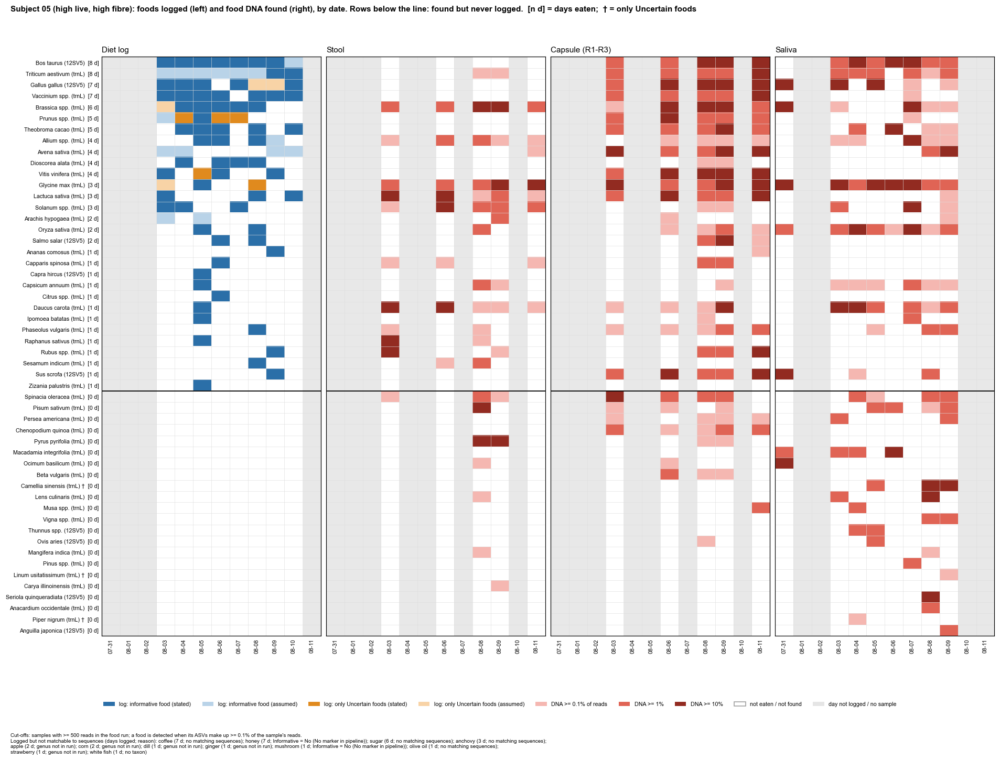

subject 05: saved 07_subject_05_log_vs_sequencing.png, 07_subject_05_log_vs_sequencing.pdf, 07_subject_05_log_vs_sequencing.csv
  logged but not matchable: coffee (7 d; no matching sequences); honey (7 d; Informative = No (No marker in pipeline)); sugar (6 d; no matching sequences); anchovy (3 d; no matching sequences); apple (2 d; genus not in run); corn (2 d; genus not in run); dill (1 d; genus not in run); ginger (1 d; genus not in run); mushroom (1 d; Informative = No (No marker in pipeline)); olive oil (1 d; no matching sequences); strawberry (1 d; genus not in run); white fish (1 d; no taxon)


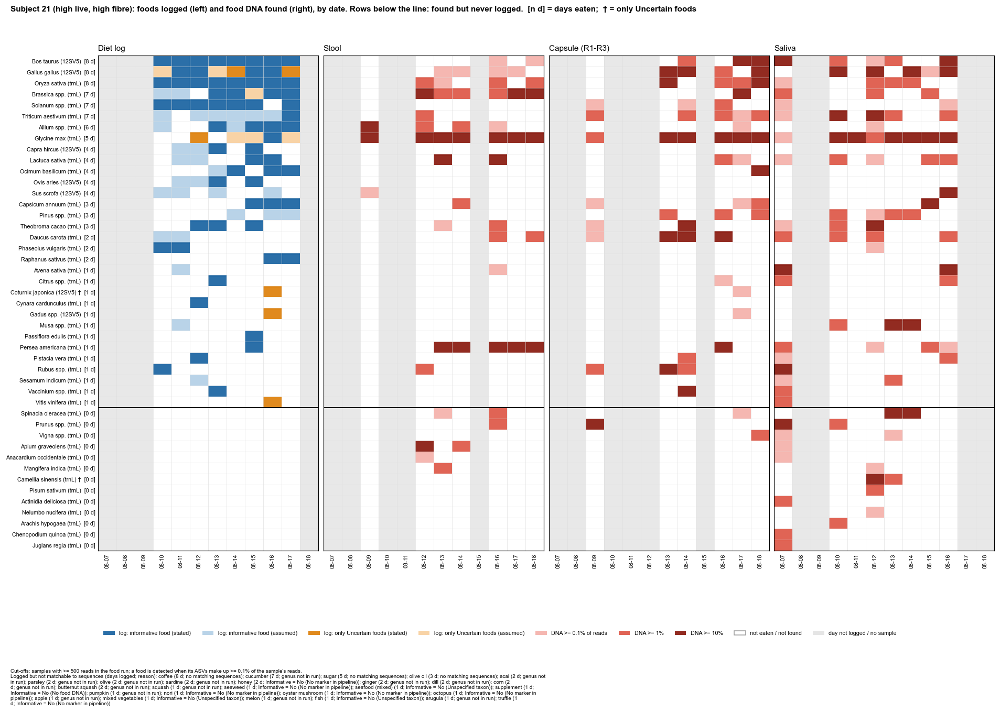

subject 21: saved 07_subject_21_log_vs_sequencing.png, 07_subject_21_log_vs_sequencing.pdf, 07_subject_21_log_vs_sequencing.csv
  logged but not matchable: coffee (8 d; no matching sequences); cucumber (7 d; genus not in run); sugar (5 d; no matching sequences); olive oil (3 d; no matching sequences); acai (2 d; genus not in run); parsley (2 d; genus not in run); olive (2 d; genus not in run); sardine (2 d; genus not in run); honey (2 d; Informative = No (No marker in pipeline)); ginger (2 d; genus not in run); dill (2 d; genus not in run); corn (2 d; genus not in run); butternut squash (2 d; genus not in run); squash (1 d; genus not in run); seaweed (1 d; Informative = No (No marker in pipeline)); seafood (mixed) (1 d; Informative = No (Unspecified taxon)); supplement (1 d; Informative = No (No food DNA)); pumpkin (1 d; genus not in run); nori (1 d; Informative = No (No marker in pipeline)); oyster mushroom (1 d; Informative = No (No marker in pipeline)); octopus (1 d; Informative = N

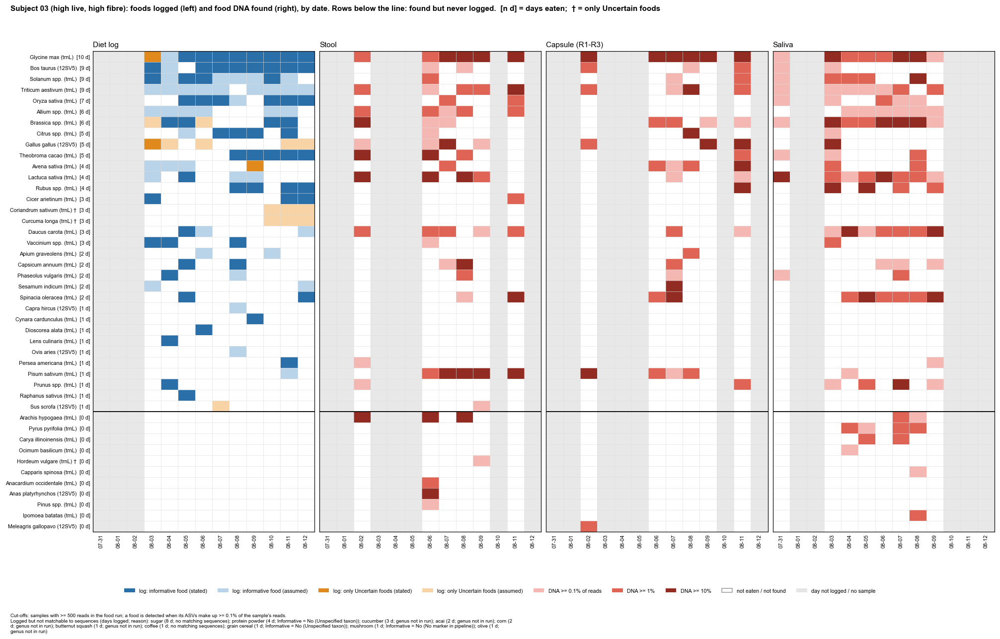

subject 03: saved 07_subject_03_log_vs_sequencing.png, 07_subject_03_log_vs_sequencing.pdf, 07_subject_03_log_vs_sequencing.csv
  logged but not matchable: sugar (8 d; no matching sequences); protein powder (4 d; Informative = No (Unspecified taxon)); cucumber (3 d; genus not in run); acai (2 d; genus not in run); corn (2 d; genus not in run); butternut squash (1 d; genus not in run); coffee (1 d; no matching sequences); grain cereal (1 d; Informative = No (Unspecified taxon)); mushroom (1 d; Informative = No (No marker in pipeline)); olive (1 d; genus not in run)


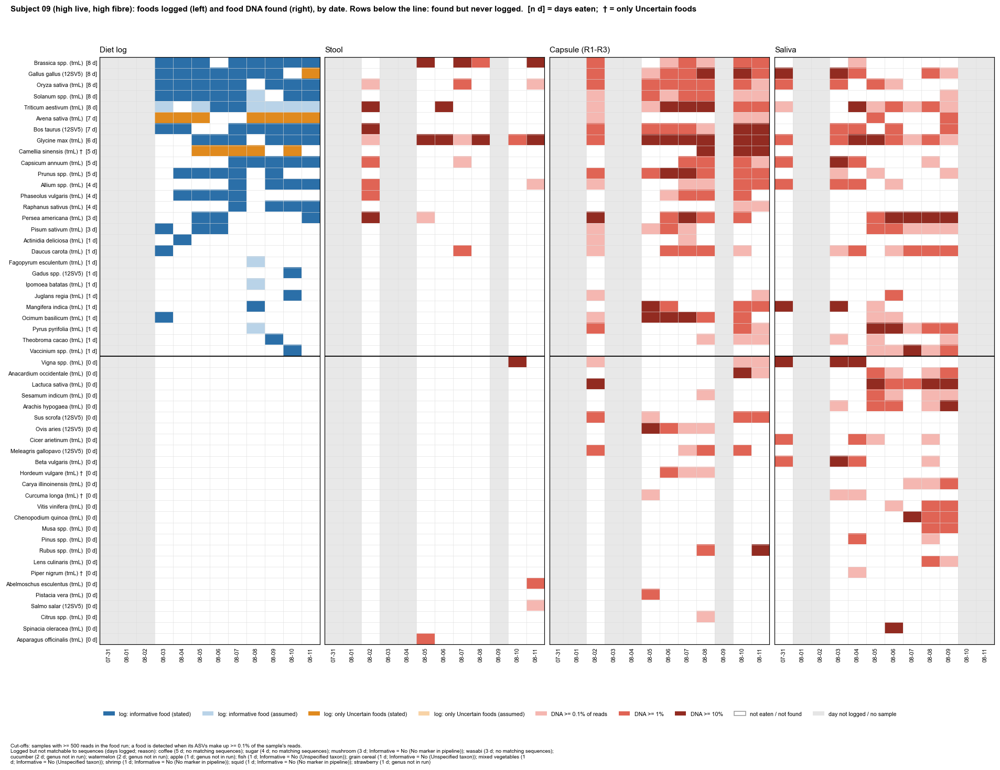

subject 09: saved 07_subject_09_log_vs_sequencing.png, 07_subject_09_log_vs_sequencing.pdf, 07_subject_09_log_vs_sequencing.csv
  logged but not matchable: coffee (5 d; no matching sequences); sugar (4 d; no matching sequences); mushroom (3 d; Informative = No (No marker in pipeline)); wasabi (3 d; no matching sequences); cucumber (2 d; genus not in run); watermelon (2 d; genus not in run); apple (1 d; genus not in run); fish (1 d; Informative = No (Unspecified taxon)); grain cereal (1 d; Informative = No (Unspecified taxon)); mixed vegetables (1 d; Informative = No (Unspecified taxon)); shrimp (1 d; Informative = No (No marker in pipeline)); squid (1 d; Informative = No (No marker in pipeline)); strawberry (1 d; genus not in run)


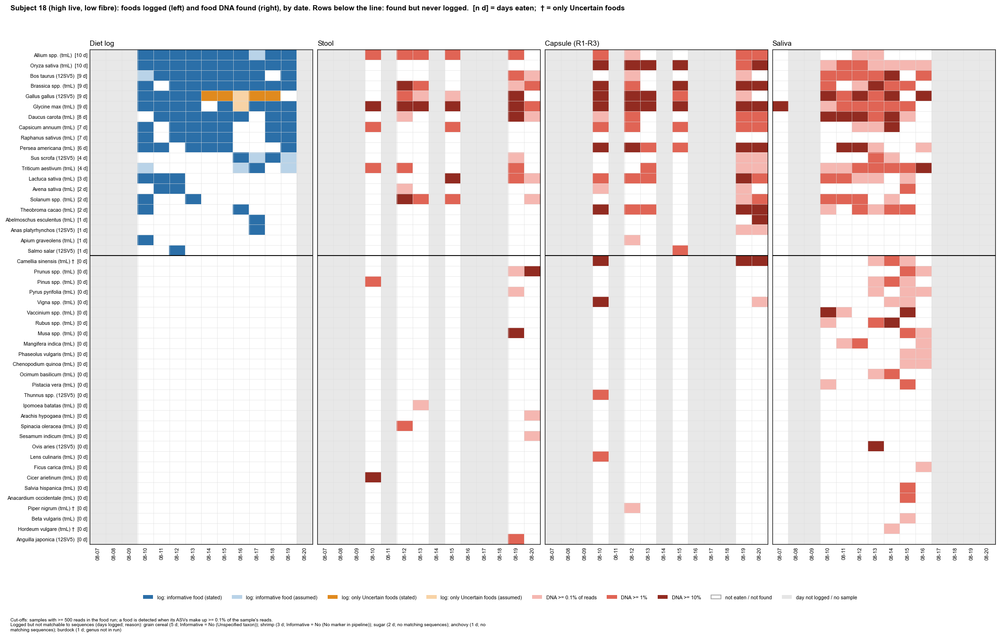

subject 18: saved 07_subject_18_log_vs_sequencing.png, 07_subject_18_log_vs_sequencing.pdf, 07_subject_18_log_vs_sequencing.csv
  logged but not matchable: grain cereal (5 d; Informative = No (Unspecified taxon)); shrimp (3 d; Informative = No (No marker in pipeline)); sugar (2 d; no matching sequences); anchovy (1 d; no matching sequences); burdock (1 d; genus not in run)


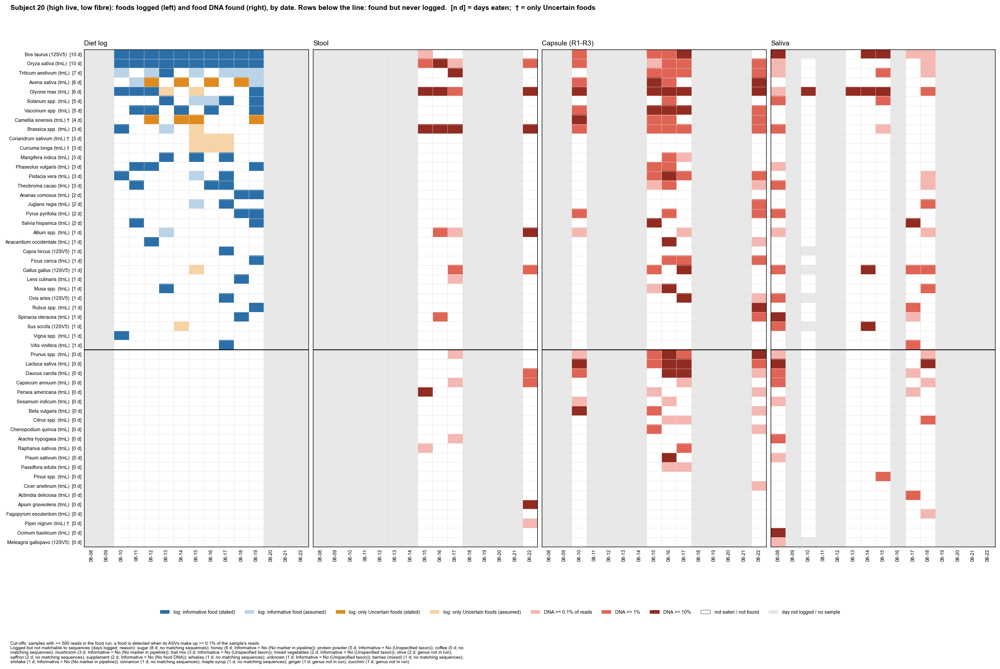

subject 20: saved 07_subject_20_log_vs_sequencing.png, 07_subject_20_log_vs_sequencing.pdf, 07_subject_20_log_vs_sequencing.csv
  logged but not matchable: sugar (8 d; no matching sequences); honey (6 d; Informative = No (No marker in pipeline)); protein powder (5 d; Informative = No (Unspecified taxon)); coffee (5 d; no matching sequences); mushroom (3 d; Informative = No (No marker in pipeline)); trail mix (3 d; Informative = No (Unspecified taxon)); mixed vegetables (2 d; Informative = No (Unspecified taxon)); olive (2 d; genus not in run); saffron (2 d; no matching sequences); supplement (2 d; Informative = No (No food DNA)); whiskey (1 d; no matching sequences); unknown (1 d; Informative = No (Unspecified taxon)); berries (mixed) (1 d; no matching sequences); shiitake (1 d; Informative = No (No marker in pipeline)); cinnamon (1 d; no matching sequences); maple syrup (1 d; no matching sequences); ginger (1 d; genus not in run); zucchini (1 d; genus not in run)


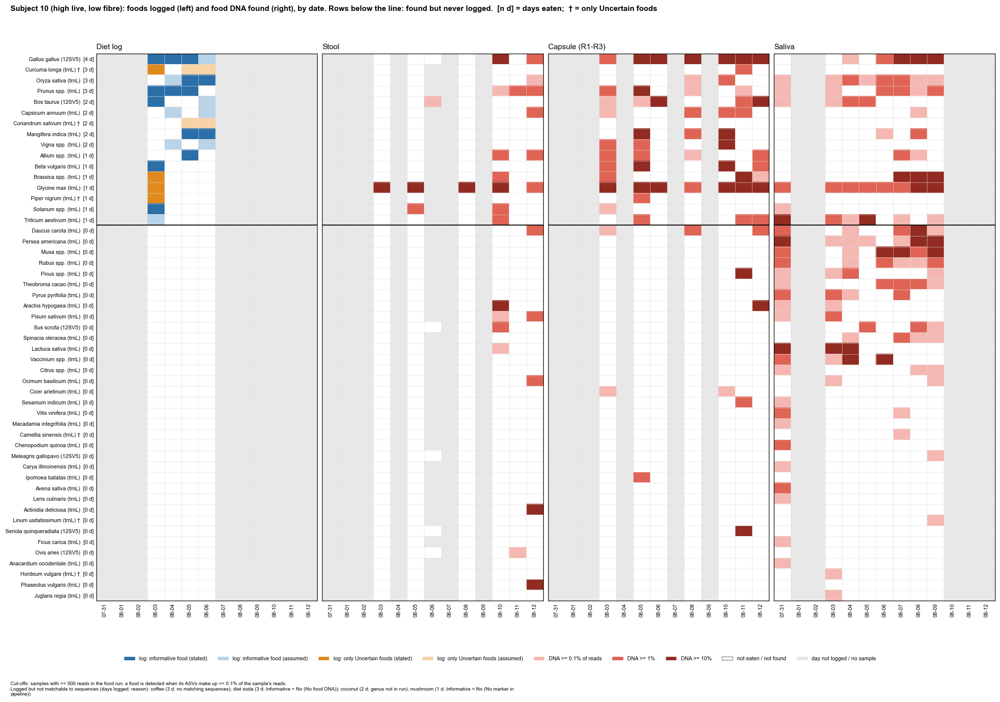

subject 10: saved 07_subject_10_log_vs_sequencing.png, 07_subject_10_log_vs_sequencing.pdf, 07_subject_10_log_vs_sequencing.csv
  logged but not matchable: coffee (3 d; no matching sequences); diet soda (3 d; Informative = No (No food DNA)); coconut (2 d; genus not in run); mushroom (1 d; Informative = No (No marker in pipeline))


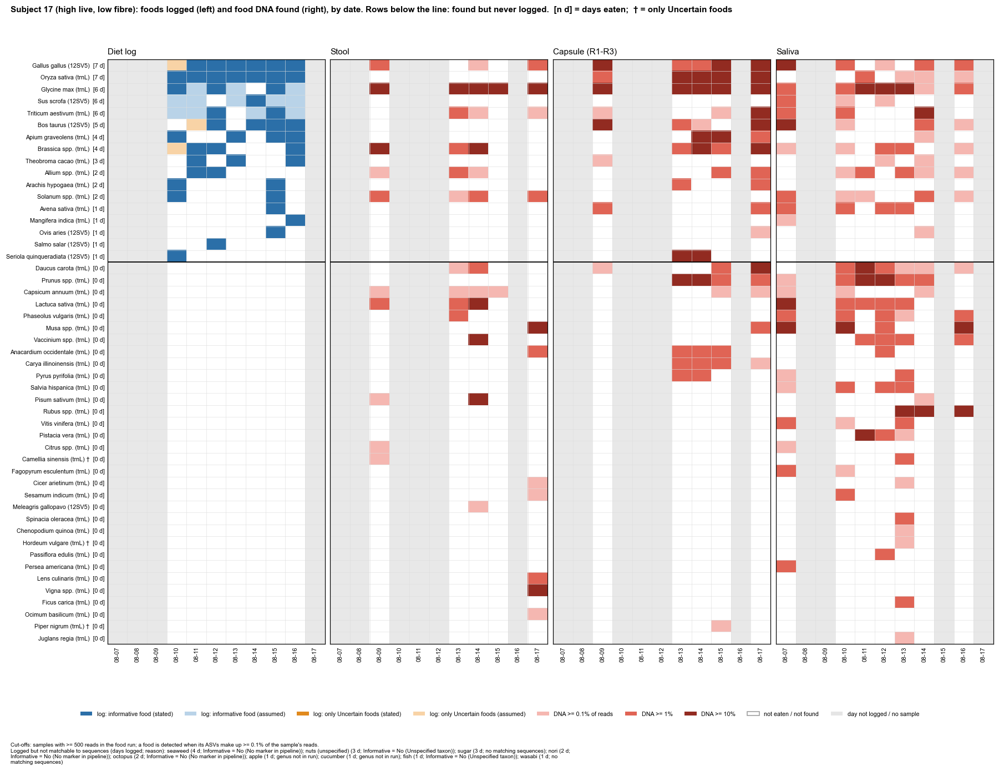

subject 17: saved 07_subject_17_log_vs_sequencing.png, 07_subject_17_log_vs_sequencing.pdf, 07_subject_17_log_vs_sequencing.csv
  logged but not matchable: seaweed (4 d; Informative = No (No marker in pipeline)); nuts (unspecified) (3 d; Informative = No (Unspecified taxon)); sugar (3 d; no matching sequences); nori (2 d; Informative = No (No marker in pipeline)); octopus (2 d; Informative = No (No marker in pipeline)); apple (1 d; genus not in run); cucumber (1 d; genus not in run); fish (1 d; Informative = No (Unspecified taxon)); wasabi (1 d; no matching sequences)


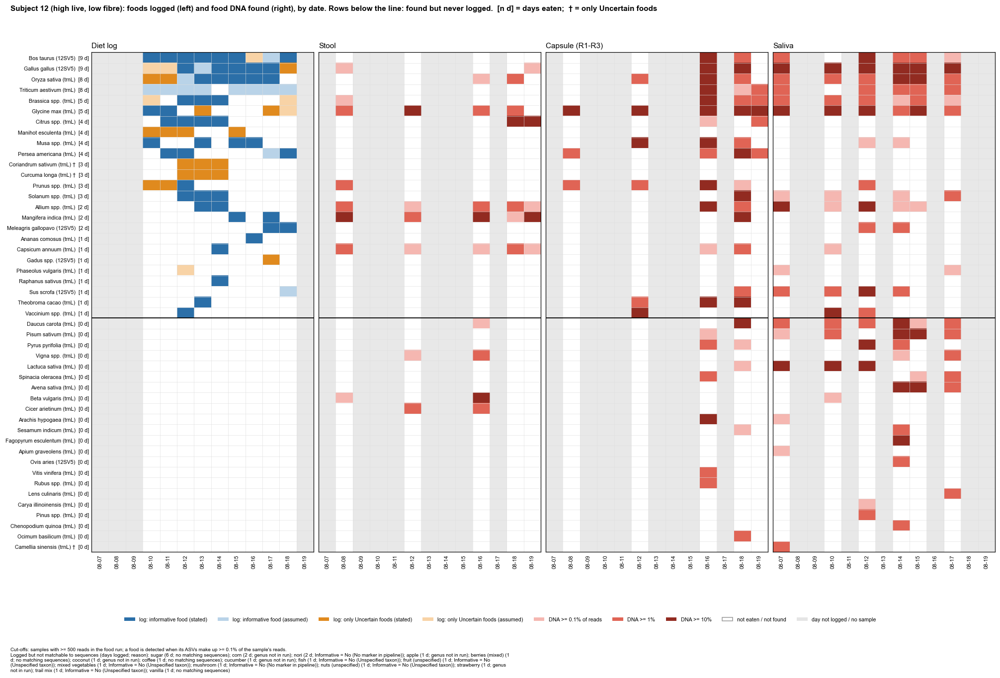

subject 12: saved 07_subject_12_log_vs_sequencing.png, 07_subject_12_log_vs_sequencing.pdf, 07_subject_12_log_vs_sequencing.csv
  logged but not matchable: sugar (6 d; no matching sequences); corn (2 d; genus not in run); nori (2 d; Informative = No (No marker in pipeline)); apple (1 d; genus not in run); berries (mixed) (1 d; no matching sequences); coconut (1 d; genus not in run); coffee (1 d; no matching sequences); cucumber (1 d; genus not in run); fish (1 d; Informative = No (Unspecified taxon)); fruit (unspecified) (1 d; Informative = No (Unspecified taxon)); mixed vegetables (1 d; Informative = No (Unspecified taxon)); mushroom (1 d; Informative = No (No marker in pipeline)); nuts (unspecified) (1 d; Informative = No (Unspecified taxon)); strawberry (1 d; genus not in run); trail mix (1 d; Informative = No (Unspecified taxon)); vanilla (1 d; no matching sequences)


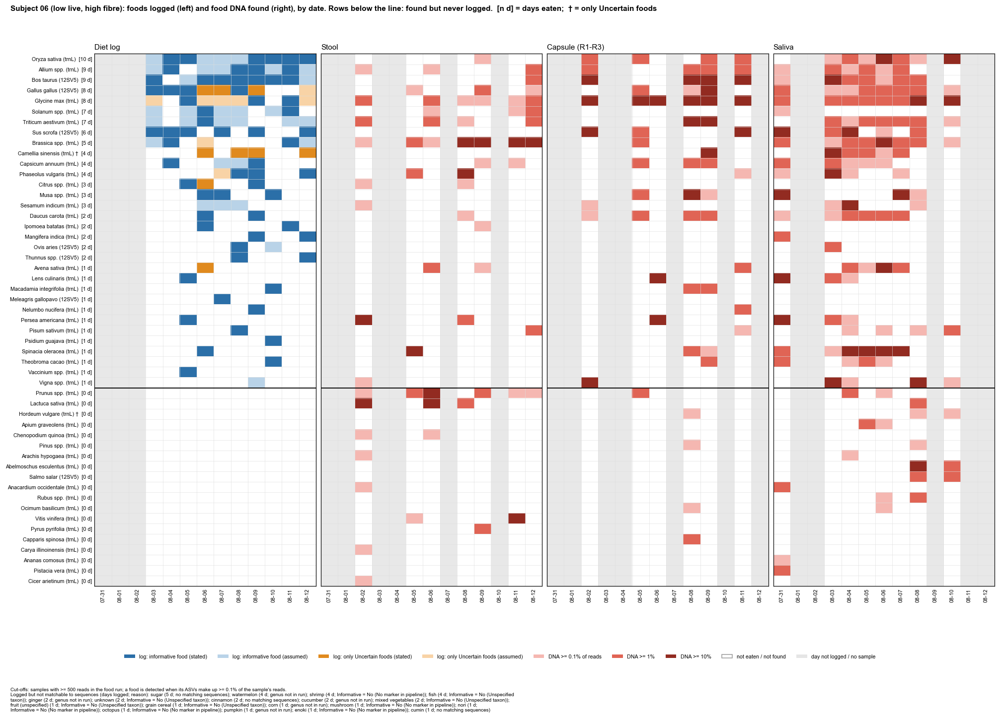

subject 06: saved 07_subject_06_log_vs_sequencing.png, 07_subject_06_log_vs_sequencing.pdf, 07_subject_06_log_vs_sequencing.csv
  logged but not matchable: sugar (5 d; no matching sequences); watermelon (4 d; genus not in run); shrimp (4 d; Informative = No (No marker in pipeline)); fish (4 d; Informative = No (Unspecified taxon)); ginger (2 d; genus not in run); unknown (2 d; Informative = No (Unspecified taxon)); cinnamon (2 d; no matching sequences); cucumber (2 d; genus not in run); mixed vegetables (2 d; Informative = No (Unspecified taxon)); fruit (unspecified) (1 d; Informative = No (Unspecified taxon)); grain cereal (1 d; Informative = No (Unspecified taxon)); corn (1 d; genus not in run); mushroom (1 d; Informative = No (No marker in pipeline)); nori (1 d; Informative = No (No marker in pipeline)); octopus (1 d; Informative = No (No marker in pipeline)); pumpkin (1 d; genus not in run); enoki (1 d; Informative = No (No marker in pipeline)); cumin (1 d; no matching sequences)


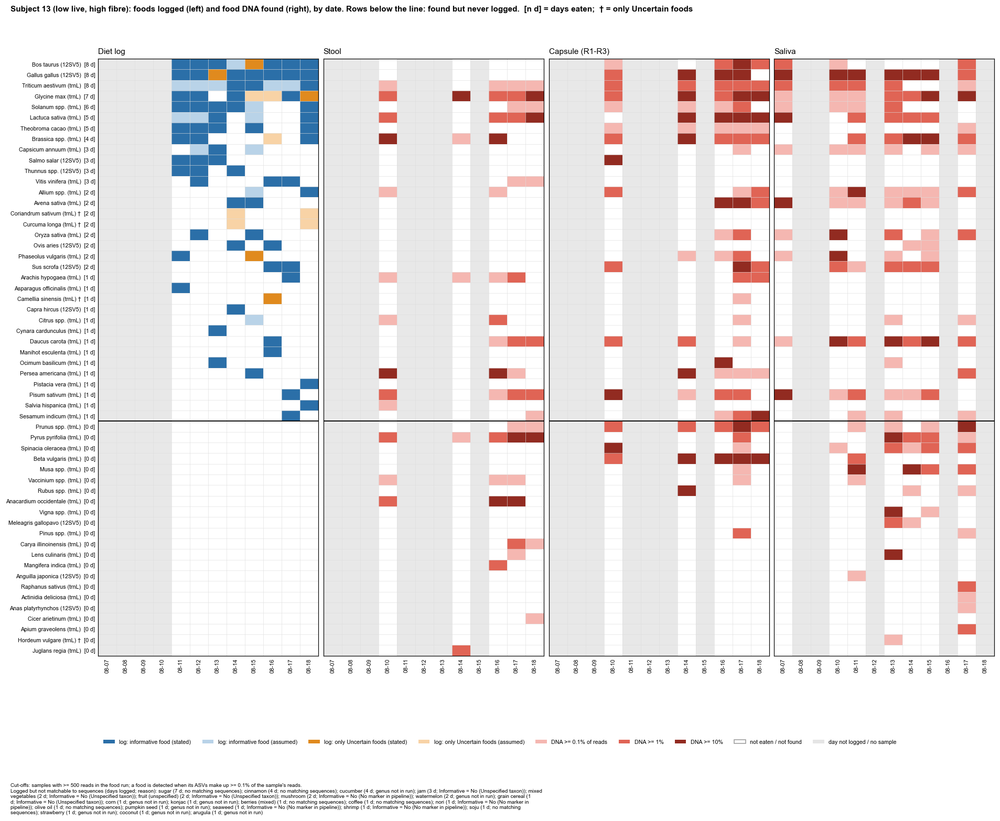

subject 13: saved 07_subject_13_log_vs_sequencing.png, 07_subject_13_log_vs_sequencing.pdf, 07_subject_13_log_vs_sequencing.csv
  logged but not matchable: sugar (7 d; no matching sequences); cinnamon (4 d; no matching sequences); cucumber (4 d; genus not in run); jam (3 d; Informative = No (Unspecified taxon)); mixed vegetables (2 d; Informative = No (Unspecified taxon)); fruit (unspecified) (2 d; Informative = No (Unspecified taxon)); mushroom (2 d; Informative = No (No marker in pipeline)); watermelon (2 d; genus not in run); grain cereal (1 d; Informative = No (Unspecified taxon)); corn (1 d; genus not in run); konjac (1 d; genus not in run); berries (mixed) (1 d; no matching sequences); coffee (1 d; no matching sequences); nori (1 d; Informative = No (No marker in pipeline)); olive oil (1 d; no matching sequences); pumpkin seed (1 d; genus not in run); seaweed (1 d; Informative = No (No marker in pipeline)); shrimp (1 d; Informative = No (No marker in pipeline)); soju (1 d; no mat

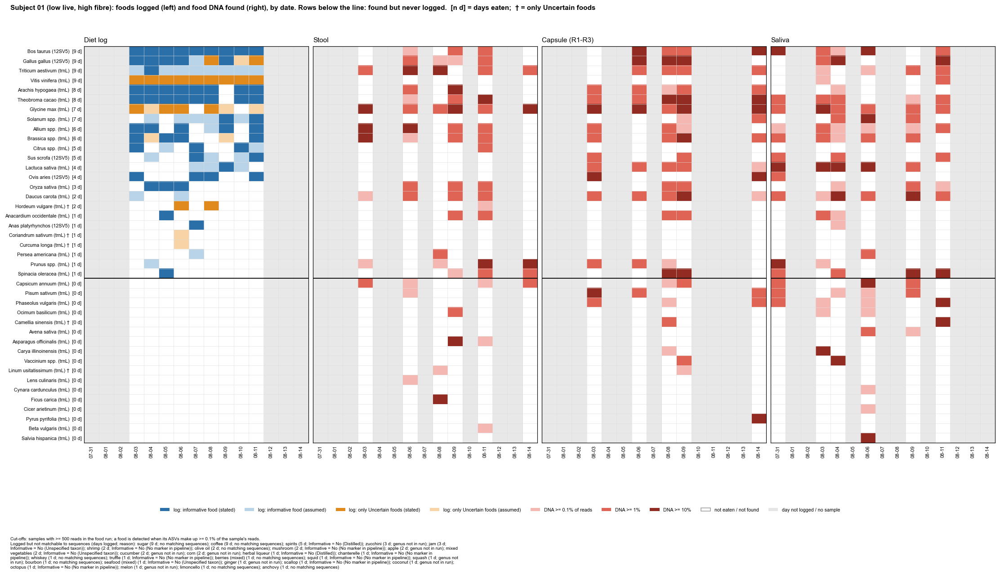

subject 01: saved 07_subject_01_log_vs_sequencing.png, 07_subject_01_log_vs_sequencing.pdf, 07_subject_01_log_vs_sequencing.csv
  logged but not matchable: sugar (9 d; no matching sequences); coffee (9 d; no matching sequences); spirits (5 d; Informative = No (Distilled)); zucchini (3 d; genus not in run); jam (3 d; Informative = No (Unspecified taxon)); shrimp (2 d; Informative = No (No marker in pipeline)); olive oil (2 d; no matching sequences); mushroom (2 d; Informative = No (No marker in pipeline)); apple (2 d; genus not in run); mixed vegetables (2 d; Informative = No (Unspecified taxon)); cucumber (2 d; genus not in run); corn (2 d; genus not in run); herbal liqueur (1 d; Informative = No (Distilled)); chanterelle (1 d; Informative = No (No marker in pipeline)); whiskey (1 d; no matching sequences); truffle (1 d; Informative = No (No marker in pipeline)); berries (mixed) (1 d; no matching sequences); squid (1 d; Informative = No (No marker in pipeline)); squash (1 d; genus not 

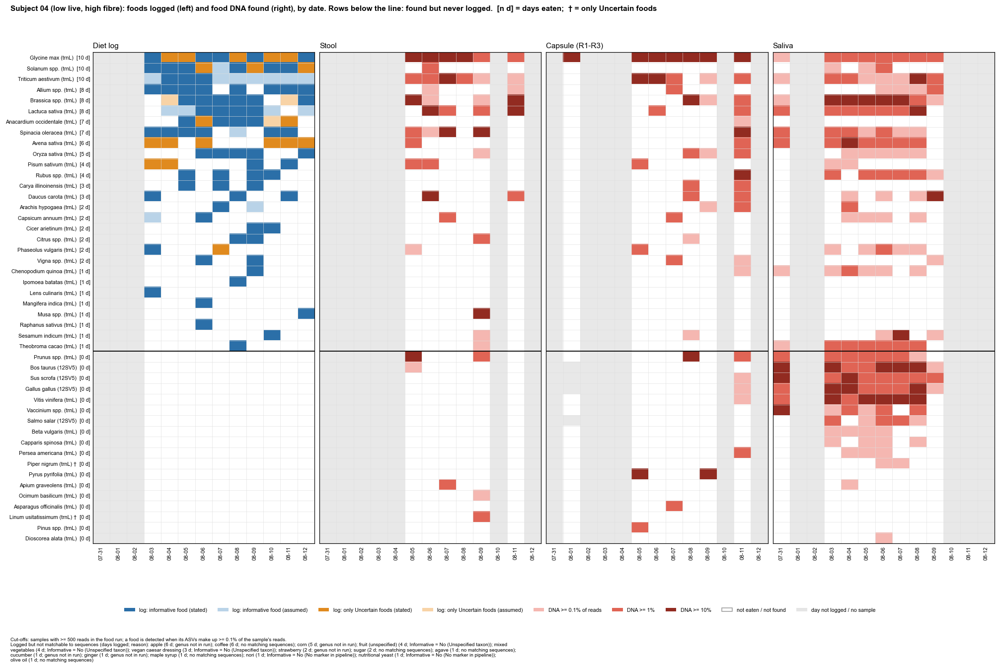

subject 04: saved 07_subject_04_log_vs_sequencing.png, 07_subject_04_log_vs_sequencing.pdf, 07_subject_04_log_vs_sequencing.csv
  logged but not matchable: apple (6 d; genus not in run); coffee (6 d; no matching sequences); corn (5 d; genus not in run); fruit (unspecified) (4 d; Informative = No (Unspecified taxon)); mixed vegetables (4 d; Informative = No (Unspecified taxon)); vegan caesar dressing (3 d; Informative = No (Unspecified taxon)); strawberry (2 d; genus not in run); sugar (2 d; no matching sequences); agave (1 d; no matching sequences); cucumber (1 d; genus not in run); ginger (1 d; genus not in run); maple syrup (1 d; no matching sequences); nori (1 d; Informative = No (No marker in pipeline)); nutritional yeast (1 d; Informative = No (No marker in pipeline)); olive oil (1 d; no matching sequences)


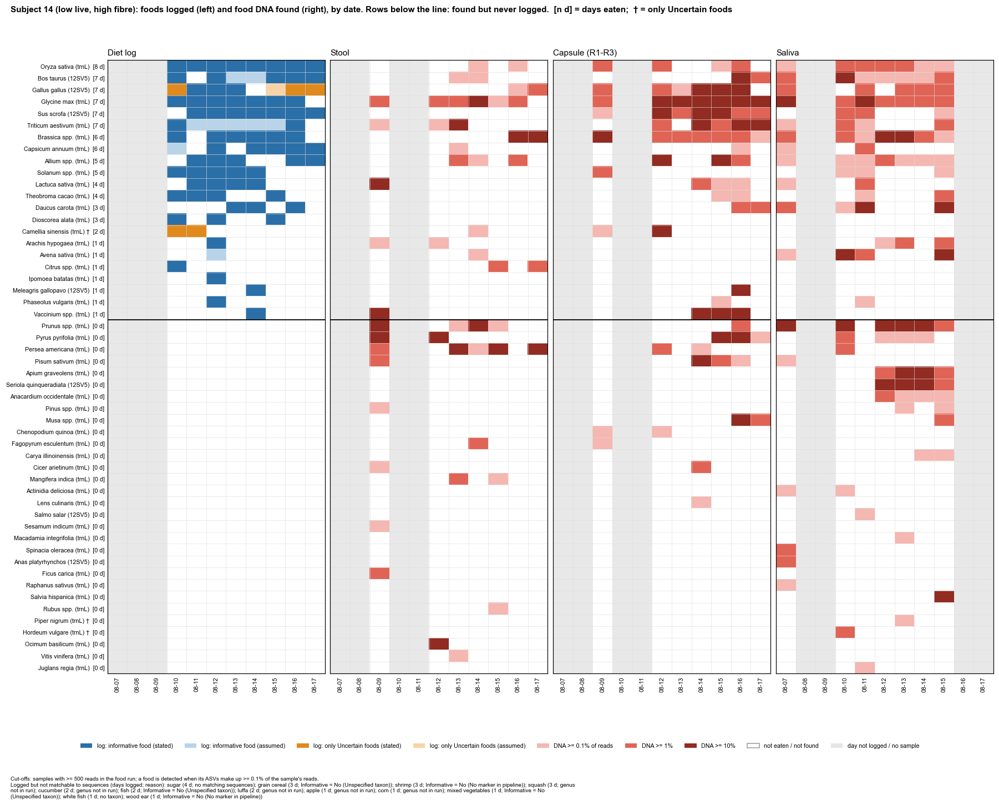

subject 14: saved 07_subject_14_log_vs_sequencing.png, 07_subject_14_log_vs_sequencing.pdf, 07_subject_14_log_vs_sequencing.csv
  logged but not matchable: sugar (4 d; no matching sequences); grain cereal (3 d; Informative = No (Unspecified taxon)); shrimp (3 d; Informative = No (No marker in pipeline)); squash (3 d; genus not in run); cucumber (2 d; genus not in run); fish (2 d; Informative = No (Unspecified taxon)); luffa (2 d; genus not in run); apple (1 d; genus not in run); corn (1 d; genus not in run); mixed vegetables (1 d; Informative = No (Unspecified taxon)); white fish (1 d; no taxon); wood ear (1 d; Informative = No (No marker in pipeline))


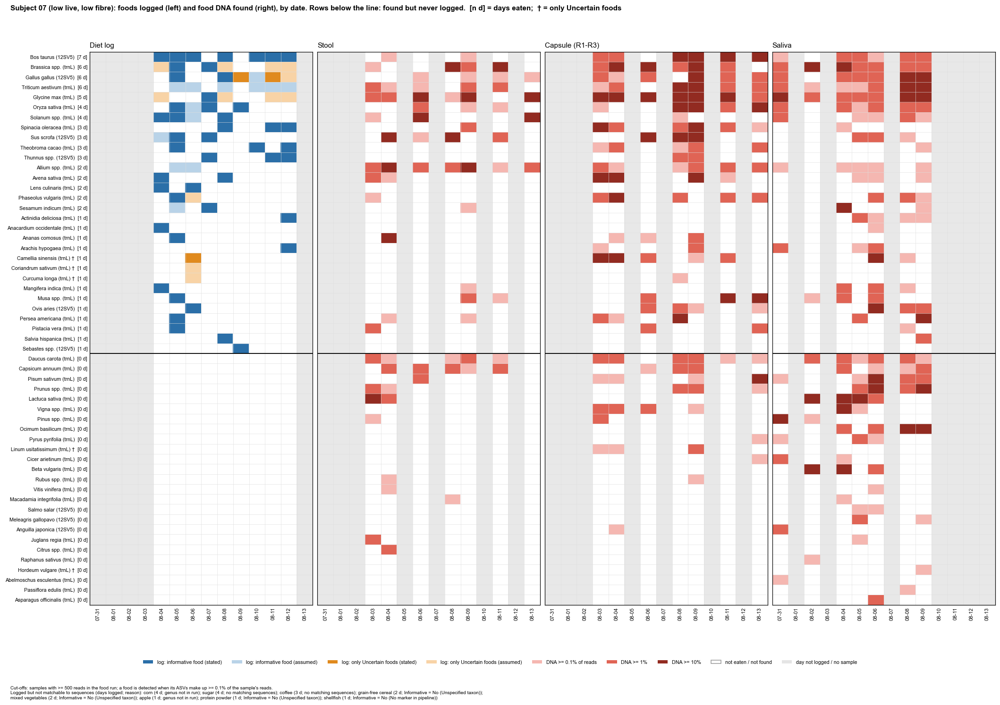

subject 07: saved 07_subject_07_log_vs_sequencing.png, 07_subject_07_log_vs_sequencing.pdf, 07_subject_07_log_vs_sequencing.csv
  logged but not matchable: corn (4 d; genus not in run); sugar (4 d; no matching sequences); coffee (3 d; no matching sequences); grain-free cereal (2 d; Informative = No (Unspecified taxon)); mixed vegetables (2 d; Informative = No (Unspecified taxon)); apple (1 d; genus not in run); protein powder (1 d; Informative = No (Unspecified taxon)); shellfish (1 d; Informative = No (No marker in pipeline))


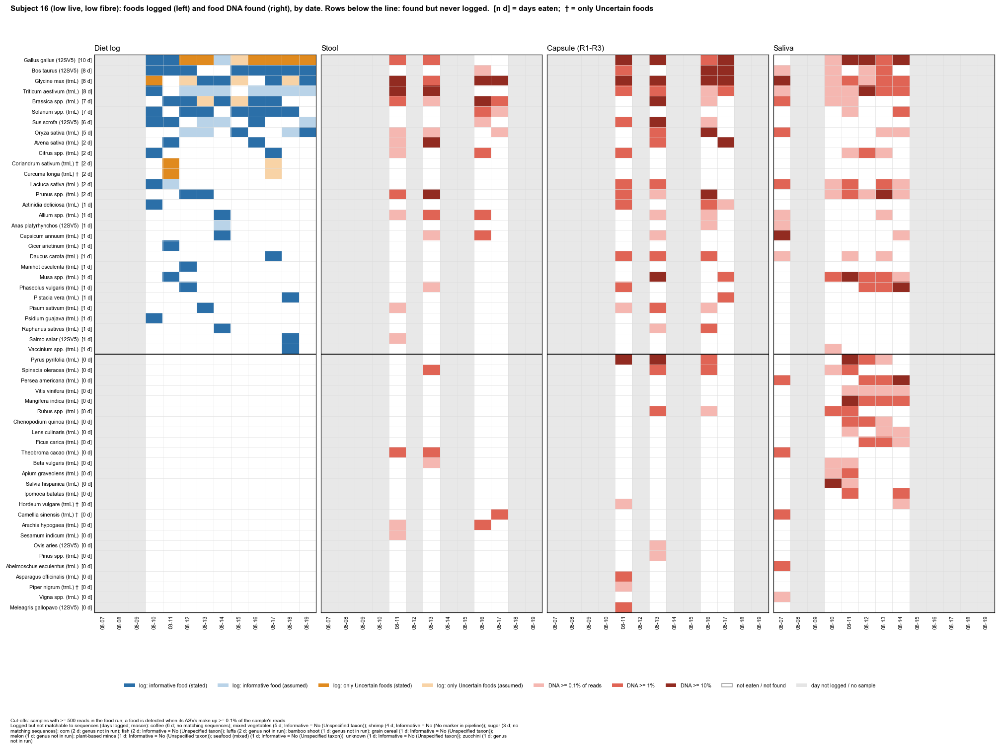

subject 16: saved 07_subject_16_log_vs_sequencing.png, 07_subject_16_log_vs_sequencing.pdf, 07_subject_16_log_vs_sequencing.csv
  logged but not matchable: coffee (6 d; no matching sequences); mixed vegetables (5 d; Informative = No (Unspecified taxon)); shrimp (4 d; Informative = No (No marker in pipeline)); sugar (3 d; no matching sequences); corn (2 d; genus not in run); fish (2 d; Informative = No (Unspecified taxon)); luffa (2 d; genus not in run); bamboo shoot (1 d; genus not in run); grain cereal (1 d; Informative = No (Unspecified taxon)); melon (1 d; genus not in run); plant-based mince (1 d; Informative = No (Unspecified taxon)); seafood (mixed) (1 d; Informative = No (Unspecified taxon)); unknown (1 d; Informative = No (Unspecified taxon)); zucchini (1 d; genus not in run)


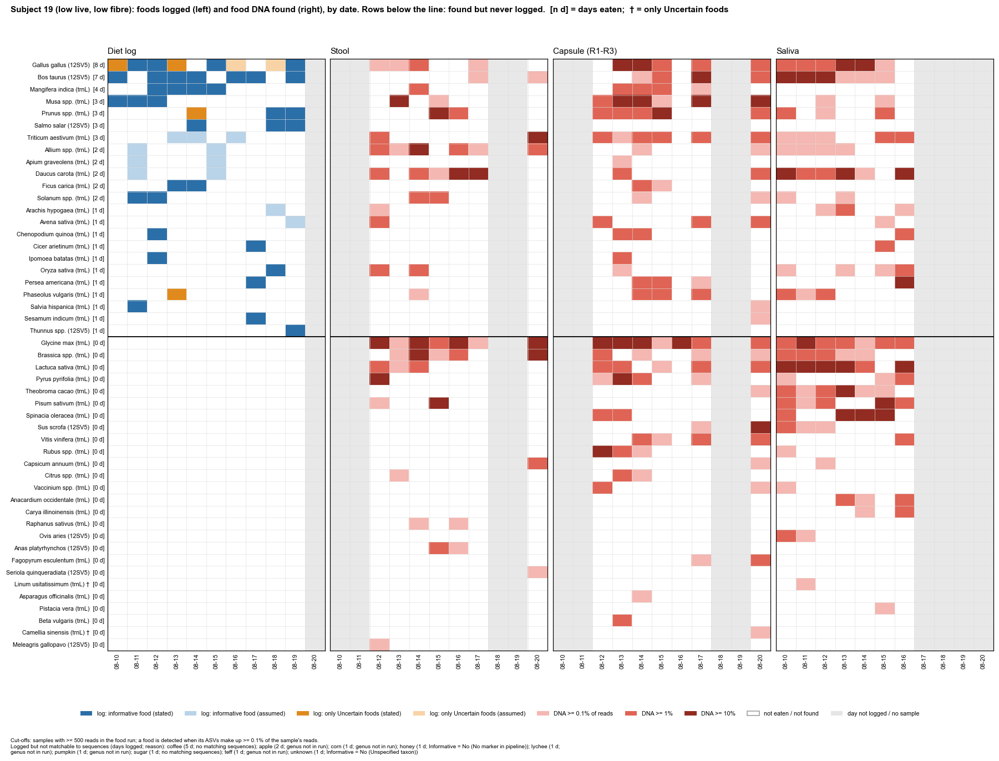

subject 19: saved 07_subject_19_log_vs_sequencing.png, 07_subject_19_log_vs_sequencing.pdf, 07_subject_19_log_vs_sequencing.csv
  logged but not matchable: coffee (5 d; no matching sequences); apple (2 d; genus not in run); corn (1 d; genus not in run); honey (1 d; Informative = No (No marker in pipeline)); lychee (1 d; genus not in run); pumpkin (1 d; genus not in run); sugar (1 d; no matching sequences); teff (1 d; genus not in run); unknown (1 d; Informative = No (Unspecified taxon))


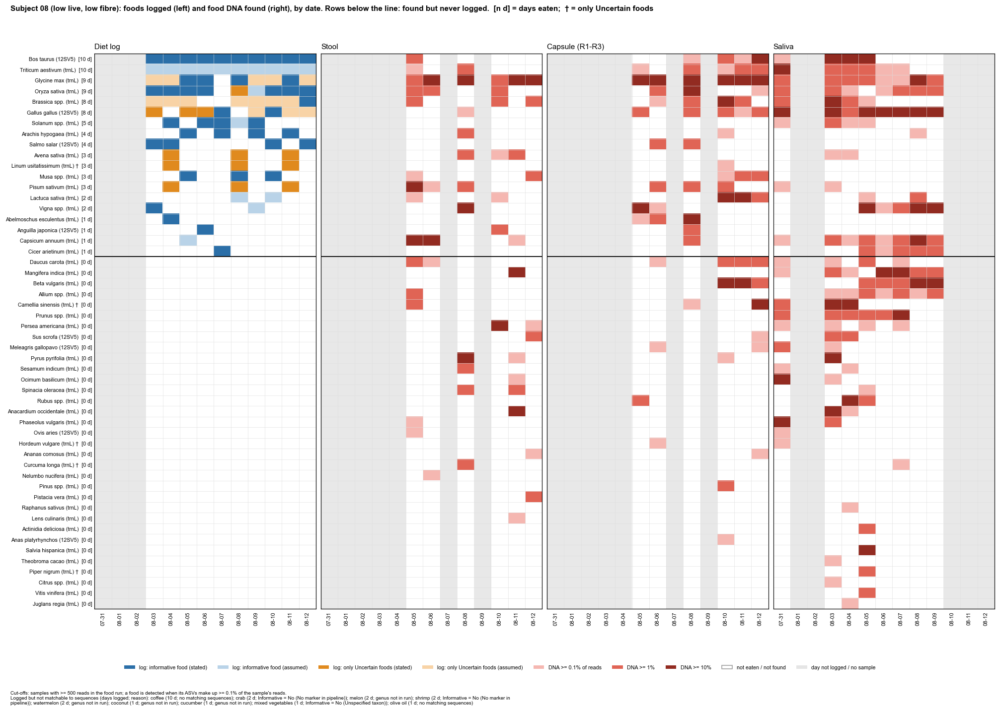

subject 08: saved 07_subject_08_log_vs_sequencing.png, 07_subject_08_log_vs_sequencing.pdf, 07_subject_08_log_vs_sequencing.csv
  logged but not matchable: coffee (10 d; no matching sequences); crab (2 d; Informative = No (No marker in pipeline)); melon (2 d; genus not in run); shrimp (2 d; Informative = No (No marker in pipeline)); watermelon (2 d; genus not in run); coconut (1 d; genus not in run); cucumber (1 d; genus not in run); mixed vegetables (1 d; Informative = No (Unspecified taxon)); olive oil (1 d; no matching sequences)


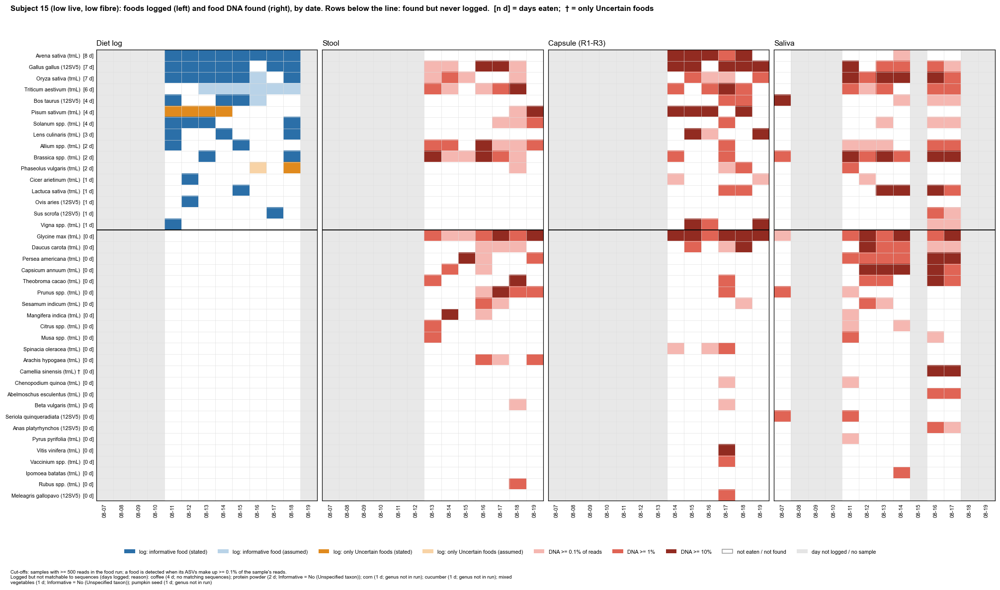

subject 15: saved 07_subject_15_log_vs_sequencing.png, 07_subject_15_log_vs_sequencing.pdf, 07_subject_15_log_vs_sequencing.csv
  logged but not matchable: coffee (4 d; no matching sequences); protein powder (2 d; Informative = No (Unspecified taxon)); corn (1 d; genus not in run); cucumber (1 d; genus not in run); mixed vegetables (1 d; Informative = No (Unspecified taxon)); pumpkin seed (1 d; genus not in run)


In [12]:
for subj in grp.index:
    fig, long = subject_figure(subj)
    files = DL.save(fig, f"07_subject_{subj}_log_vs_sequencing", long, FIG_FOLDER)
    plt.show()
    u = unmatched[unmatched.subject == subj].sort_values("days", ascending=False)
    print(f"subject {subj}: saved", ", ".join(f.name for f in files))
    print("  logged but not matchable:", "none" if u.empty else "; ".join(f"{r.ingredient} ({r.days} d; {r.reason})" for r in u.itertuples(index=False)))
unmatched.to_csv(_paths.FIG_DIR / FIG_FOLDER / "07_logged_not_matchable.csv", index=False)

**How to read it:** each row is one food taxon (what sequencing can tell apart; e.g. *Bos taurus* = milk, cheese, beef,
butter); `[n d]` is the number of days the subject logged it, so the regularly eaten foods are at the top. Read **across** a
row: blue tiles are days on which an informative food of that taxon was logged, orange tiles days on which the taxon was
reached **only** through `Uncertain` foods (e.g. egg for *Gallus gallus*; † marks taxa reached only that way). Red tiles in the
stool, capsule and saliva panels are days on which its DNA was found (darker = larger share of reads). Columns are calendar
dates, the same in all four panels, so food eaten one day should appear in stool one to a few days later. Rows below the black
line were found but never logged. The footnote lists logged foods that cannot be matched to sequences at all.

### Two definitions of "eaten" used in 0.8 and 0.9
The lexicon column `Informative for sequencing? (Yes / Uncertain / No)` rates, before any sequencing, whether a food's DNA
should be detectable (definitions from the workbook README):
- **Yes:** the marker covers it, the log names a single taxon, and DNA is expected to survive (whole or lightly processed
  foods: wheat, rice, chicken, tomato, ...).
- **Uncertain:** DNA reduced, trace, low or unproven: processed (coffee, beer, soy sauce), trace amounts (spices), refined
  (sugar, oil), isolated or fat (butter, whey, gelatin), low-DNA (egg), or only a group/product named. The README says a miss
  should not be counted as a false negative.
- **No:** no marker covers it (mushroom, seaweed, shellfish) or no single taxon is named. Never counted.

Sections 0.8 and 0.9 are drawn twice:
- **Version "Yes":** a food taxon counts as eaten only if a `Yes` food of that taxon was logged (68 taxa).
- **Version "Yes + Uncertain":** foods rated `Uncertain` count as eaten too (75 taxa; e.g. egg days count for *Gallus gallus*,
  butter days for *Bos taurus*, coffee would if its genus were in the run).
Comparing the two shows how much `Uncertain` foods explain DNA that looks "not logged" (precision), at the price of more
foods whose DNA is not found (recall).

In [13]:
VERSIONS = {
    "yes": {"title": "foods rated Yes", "taxa": taxa, "mt": mt, "det": det,
            "note": "Eaten = a food rated 'Yes' (DNA expected to survive) logged that day; 68 food taxa."},
    "yes_uncertain": {"title": "foods rated Yes or Uncertain", "taxa": taxa_u, "mt": mt_u, "det": det_u,
                      "note": "Eaten = a food rated 'Yes' or 'Uncertain' (processed, trace or low-DNA foods such as egg, "
                              "butter, coffee) logged that day; 75 food taxa."},
}
for v in VERSIONS.values():
    v["run"] = dict(zip(v["taxa"].taxon_id, v["taxa"].run))
    v["label"] = {t: f"{l} ({'trnL' if r == 'plants' else '12SV5'})" for t, l, r in zip(v["taxa"].taxon_id, v["taxa"].label, v["taxa"].run)}
print({k: f"{len(v['taxa'])} taxa" for k, v in VERSIONS.items()})

{'yes': '68 taxa', 'yes_uncertain': '75 taxa'}


### 0.8 Summary: are regularly eaten foods found more often?
For every subject x food taxon pair, two shares:
- **how regularly it was eaten:** the share of the subject's logged days on which it was logged (0 = never);
- **how often its DNA was found:** the share of the subject's sampling days (of that sample type, in the taxon's run) on
  which it was detected (>= 0.1% of reads).
One panel per sample type; each dot is one pair. The line connects the average detection share within bins of regularity
(never eaten; up to 25%; 25-50%; 50-75%; over 75% of days). **Expected** if sequencing reflects the log: the line rises from
left to right, and foods never eaten (x = 0) are found least. Descriptive; the Spearman rank correlation is printed but not
tested. Drawn for both definitions of "eaten".

Version 'yes' (foods rated Yes):
  Stool: pairs 1292; Spearman 0.42; average found share by regularity: never 0.06, <= 25% 0.18, 25-50% 0.29, 50-75% 0.37, > 75% 0.38
  Capsule: pairs 1292; Spearman 0.64; average found share by regularity: never 0.07, <= 25% 0.28, 25-50% 0.48, 50-75% 0.52, > 75% 0.75
  Saliva: pairs 1292; Spearman 0.46; average found share by regularity: never 0.13, <= 25% 0.27, 25-50% 0.42, 50-75% 0.58, > 75% 0.66


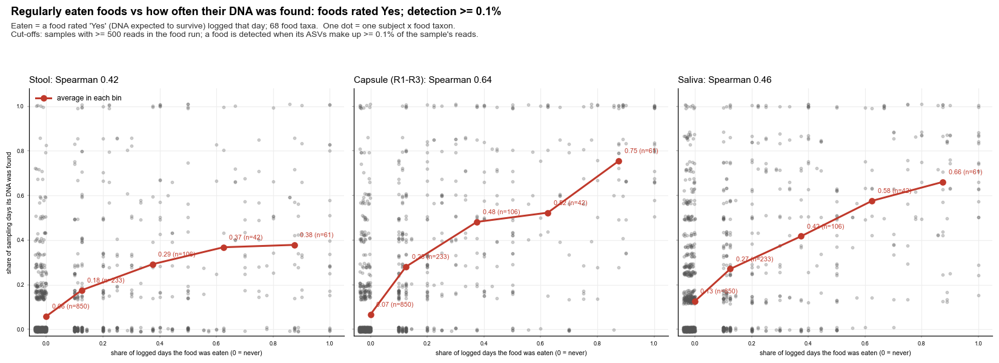

  saved: 08_regularity_vs_detection_yes.png, 08_regularity_vs_detection_yes.pdf, 08_regularity_vs_detection_yes.csv
Version 'yes_uncertain' (foods rated Yes or Uncertain):
  Stool: pairs 1425; Spearman 0.43; average found share by regularity: never 0.05, <= 25% 0.15, 25-50% 0.22, 50-75% 0.39, > 75% 0.43
  Capsule: pairs 1425; Spearman 0.64; average found share by regularity: never 0.06, <= 25% 0.24, 25-50% 0.39, 50-75% 0.59, > 75% 0.73
  Saliva: pairs 1425; Spearman 0.45; average found share by regularity: never 0.11, <= 25% 0.24, 25-50% 0.30, 50-75% 0.58, > 75% 0.69


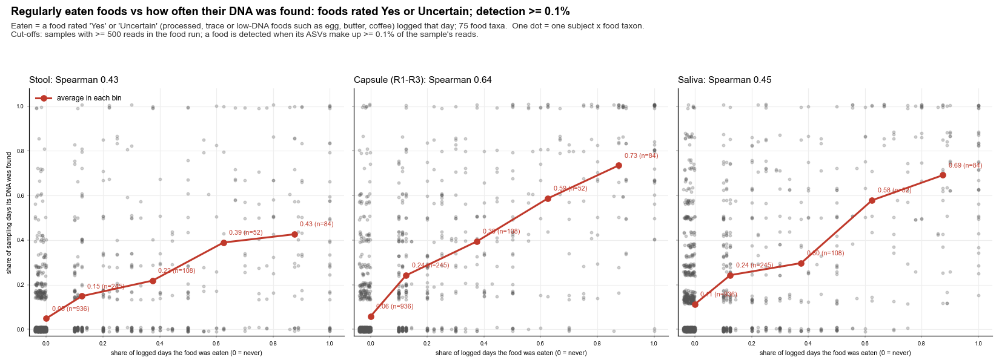

  saved: 08_regularity_vs_detection_yes_uncertain.png, 08_regularity_vs_detection_yes_uncertain.pdf, 08_regularity_vs_detection_yes_uncertain.csv


In [14]:
logged_n = entries.groupby("subject").date.nunique()
BINS = [-0.001, 0.0, 0.25, 0.5, 0.75, 1.0]
BIN_LABELS = ["never", "<= 25%", "25-50%", "50-75%", "> 75%"]
CENTRES = {"never": 0.0, "<= 25%": 0.125, "25-50%": 0.375, "50-75%": 0.625, "> 75%": 0.875}

def regularity_table(v):
    mt_v, det_v, run_v = v["mt"], v["det"], v["run"]
    eaten_days = mt_v.groupby(["subject", "taxon_id"]).date.nunique()
    sampled = det_v.assign(run=det_v.taxon_id.map(run_v)).groupby(["Subject_ID", "Sample_origin3", "run"]).date.nunique()
    found = det_v[det_v.detected].groupby(["Subject_ID", "Sample_origin3", "taxon_id"]).date.nunique()
    rows = []
    for label, origin in SAMPLE_TYPES.items():
        for subj in grp.index:
            for t, run in run_v.items():
                n = sampled.get((subj, origin, run), 0)
                if n:
                    rows.append({"sample_type": label, "subject": subj, "taxon_id": t, "taxon": v["label"][t],
                                 "eaten_share": eaten_days.get((subj, t), 0) / logged_n[subj],
                                 "found_share": found.get((subj, origin, t), 0) / n, "sampling_days": n})
    reg = pd.DataFrame(rows)
    reg["regularity"] = pd.cut(reg.eaten_share, BINS, labels=BIN_LABELS)
    return reg

def plot_regularity(reg, v, name, thr=DETECT_MIN):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)
    rng = np.random.default_rng(4)                   # fixed seed: jitter so overlapping dots stay visible
    for ax, label in zip(axes, SAMPLE_TYPES):
        d = reg[reg.sample_type == label]
        x = d.eaten_share + np.where(d.eaten_share == 0, rng.uniform(-0.04, 0.0, len(d)), 0)
        ax.scatter(x, d.found_share + rng.uniform(-0.01, 0.01, len(d)), s=8, alpha=0.25, color="#555555", zorder=2)
        m = d.groupby("regularity", observed=False).found_share.agg(["mean", "size"])
        ax.plot([CENTRES[b] for b in m.index], m["mean"], "-o", color="#C0392B", lw=2, zorder=3, label="average in each bin")
        for b, r in m.iterrows():
            ax.text(CENTRES[b] + 0.02, r["mean"] + 0.035, f"{r['mean']:.2f} (n={int(r['size'])})", ha="left", fontsize=7,
                    color="#C0392B", zorder=4)
        rho = d.eaten_share.corr(d.found_share, method="spearman")
        ax.set_title(f"{label}{' (R1-R3)' if label == 'Capsule' else ''}: Spearman {rho:.2f}", fontsize=10)
        ax.set_xlabel("share of logged days the food was eaten (0 = never)")
        ax.set_xlim(-0.06, 1.05); ax.set_ylim(-0.03, 1.08)
        ax.grid(color="#EEEEEE"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        print(f"  {label}: pairs {len(d)}; Spearman {rho:.2f}; average found share by regularity: "
              + ", ".join(f"{b} {r['mean']:.2f}" for b, r in m.iterrows()))
    axes[0].set_ylabel("share of sampling days its DNA was found")
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    fig.suptitle(f"Regularly eaten foods vs how often their DNA was found: {v['title']}; detection >= {pct(thr)}", x=0.01, y=0.99, ha="left",
                 fontweight="bold", fontsize=12)
    fig.text(0.01, 0.945, v["note"] + "  One dot = one subject x food taxon.\n" + cutoffs(thr),
             ha="left", va="top", fontsize=9, color="#333333")
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    files = DL.save(fig, name, reg, FIG_FOLDER)
    plt.show()
    print("  saved:", ", ".join(f.name for f in files))

regs = {}
for key, v in VERSIONS.items():
    print(f"Version '{key}' ({v['title']}):")
    regs[key] = regularity_table(v)
    plot_regularity(regs[key], v, f"08_regularity_vs_detection_{key}")

**How to read it:** each grey dot is one food for one subject: further right = eaten on more of their logged days, higher =
found on more of their sampling days. The red line is the average height of the dots in each regularity bin (n = pairs in
the bin). A rising line means regularly eaten foods are found more often; the height at "never" is the background (DNA found
without the food being logged). Between the two versions, pairs whose only logged source is an `Uncertain` food (e.g. egg)
move from "never" to the right; if their DNA is found, the background at "never" drops.

### 0.9 Whole-week agreement per subject: recall, precision and accuracy
Here the time series is ignored: for each subject and each food taxon, the whole week is reduced to two yes/no answers.
- **Eaten:** the subject logged a food of that taxon at least once during their diet log (definition "Yes" or "Yes + Uncertain").
- **Sequenced:** its DNA was detected (>= 0.1% of reads) in at least one of the subject's included samples of that type.

Each subject x taxon pair falls into one of four boxes, the **confusion table**:

|                   | sequenced | not sequenced |
|---|---|---|
| **eaten**         | TP (true positive)  | FN (false negative) |
| **not eaten**     | FP (false positive) | TN (true negative)  |

- **Recall** = TP / (TP + FN): of the foods a person ate, the share whose DNA was found.
- **Precision** = TP / (TP + FP): of the foods whose DNA was found, the share the person had logged.
- **Accuracy** = (TP + TN) / all pairs: the share of pairs where log and sequencing agree (eaten and found, or neither).
  Most pairs are "not eaten and not found", so accuracy is dominated by TN; read it together with the other two.

A pair is counted only if the subject has at least one included sample of that type in the taxon's run. All of a subject's
samples count, including those collected before the log started or after it ended. Capsule regions R1-R3 are combined.
Descriptive; nothing is tested. **Expected:** TP + FN + FP + TN = number of judgeable pairs; every value between 0 and 1.

In [15]:
def confusion(v, thr=DETECT_MIN, lib_used=None, runs_used=None, detect=None):
    # lib_used / runs_used: libraries and count tables to use (default: included libraries, original counts)
    # detect: function of the abundance table returning True where a taxon counts as detected (default: rel >= thr)
    lib_used = lib[lib.included] if lib_used is None else lib_used
    ab_v = FS.taxon_abundance(lib_used, v["taxa"], runs if runs_used is None else runs_used).merge(
        lib_used[["run", "library", "Subject_ID", "Sample_origin3", "reads"]], on=["run", "library"])   # dated or not
    flag = (ab_v.rel >= thr) if detect is None else detect(ab_v)
    seq_any = flag.groupby([ab_v.Subject_ID, ab_v.Sample_origin3, ab_v.taxon_id]).any()
    eaten_pairs = set(map(tuple, v["mt"][["subject", "taxon_id"]].drop_duplicates().to_numpy()))
    rows = []
    for label, origin in SAMPLE_TYPES.items():
        has_run = lib_used[lib_used.Sample_origin3 == origin].groupby("Subject_ID").run.unique().map(set)
        for subj in grp.index:
            for t, run in v["run"].items():
                if run in has_run.get(subj, set()):
                    rows.append({"sample_type": label, "subject": subj, "taxon_id": t,
                                 "eaten": (subj, t) in eaten_pairs, "sequenced": bool(seq_any.get((subj, origin, t), False))})
    pairs = pd.DataFrame(rows)
    pairs["box"] = np.select([pairs.eaten & pairs.sequenced, pairs.eaten & ~pairs.sequenced, ~pairs.eaten & pairs.sequenced],
                             ["TP", "FN", "FP"], "TN")
    return pairs

def metrics(df):
    c = df.box.value_counts().reindex(["TP", "FN", "FP", "TN"], fill_value=0)
    return pd.Series({**c.to_dict(), "pairs": int(c.sum()),
                      "recall": c.TP / (c.TP + c.FN) if c.TP + c.FN else np.nan,
                      "precision": c.TP / (c.TP + c.FP) if c.TP + c.FP else np.nan,
                      "accuracy": (c.TP + c.TN) / c.sum() if c.sum() else np.nan})

results = {}
for key, v in VERSIONS.items():
    pairs = confusion(v)
    per_subject_m = pairs.groupby(["sample_type", "subject"]).apply(metrics, include_groups=False).reset_index()
    pooled = pairs.groupby("sample_type").apply(metrics, include_groups=False).reindex(list(SAMPLE_TYPES))
    results[key] = (pairs, per_subject_m, pooled)
    ok = bool((pooled[["TP", "FN", "FP", "TN"]].sum(axis=1) == pooled.pairs).all())
    print(f"Version '{key}' ({v['title']}): check TP + FN + FP + TN = pairs: {ok}")
    print("  all subjects pooled:")
    print(pooled.round(3).to_string())
    print("  median across subjects:")
    print(per_subject_m.groupby("sample_type")[["recall", "precision", "accuracy"]].median().reindex(list(SAMPLE_TYPES)).round(3).to_string())
    print()

Version 'yes' (foods rated Yes): check TP + FN + FP + TN = pairs: True
  all subjects pooled:
                TP     FN     FP     TN   pairs  recall  precision  accuracy
sample_type                                                                 
Stool        245.0  197.0  180.0  670.0  1292.0   0.554      0.576     0.708
Capsule      346.0   96.0  165.0  685.0  1292.0   0.783      0.677     0.798
Saliva       325.0  117.0  327.0  523.0  1292.0   0.735      0.498     0.656
  median across subjects:
             recall  precision  accuracy
sample_type                             
Stool         0.593      0.609     0.706
Capsule       0.815      0.667     0.794
Saliva        0.750      0.515     0.647



Version 'yes_uncertain' (foods rated Yes or Uncertain): check TP + FN + FP + TN = pairs: True
  all subjects pooled:
                TP     FN     FP     TN   pairs  recall  precision  accuracy
sample_type                                                                 
Stool        261.0  228.0  174.0  762.0  1425.0   0.534      0.600     0.718
Capsule      372.0  117.0  166.0  770.0  1425.0   0.761      0.691     0.801
Saliva       343.0  146.0  340.0  596.0  1425.0   0.701      0.502     0.659
  median across subjects:
             recall  precision  accuracy
sample_type                             
Stool         0.565      0.621     0.720
Capsule       0.765      0.677     0.813
Saliva        0.727      0.514     0.653



#### Per-subject figures (version "Yes"; one per sample type)

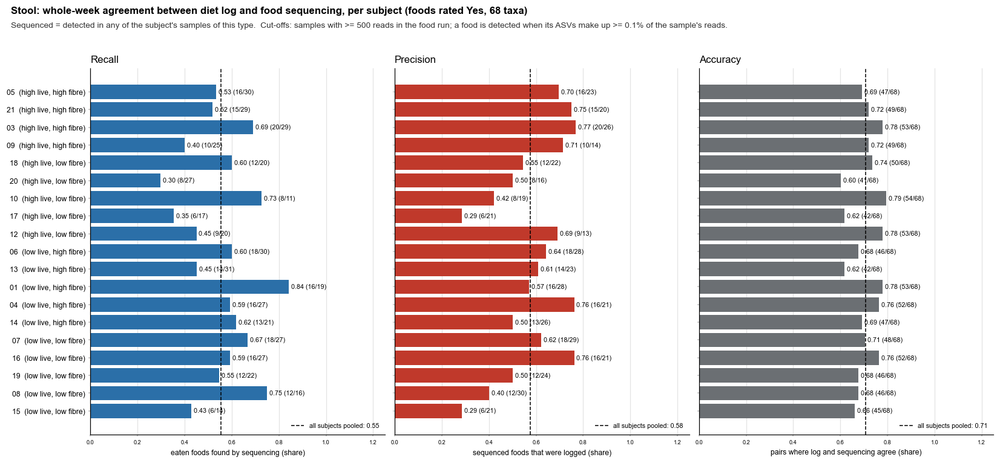

saved: 09_stool_recall_precision_accuracy.png, 09_stool_recall_precision_accuracy.pdf, 09_stool_recall_precision_accuracy.csv


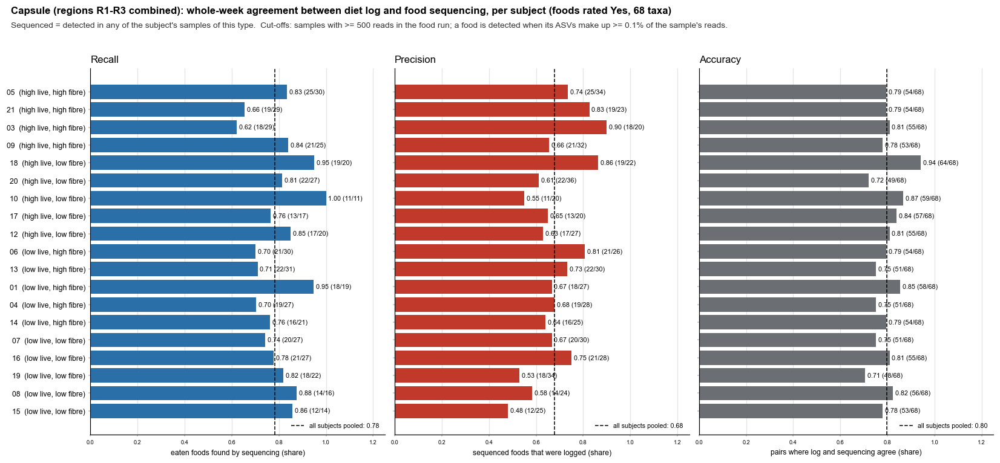

saved: 09_capsule_recall_precision_accuracy.png, 09_capsule_recall_precision_accuracy.pdf, 09_capsule_recall_precision_accuracy.csv


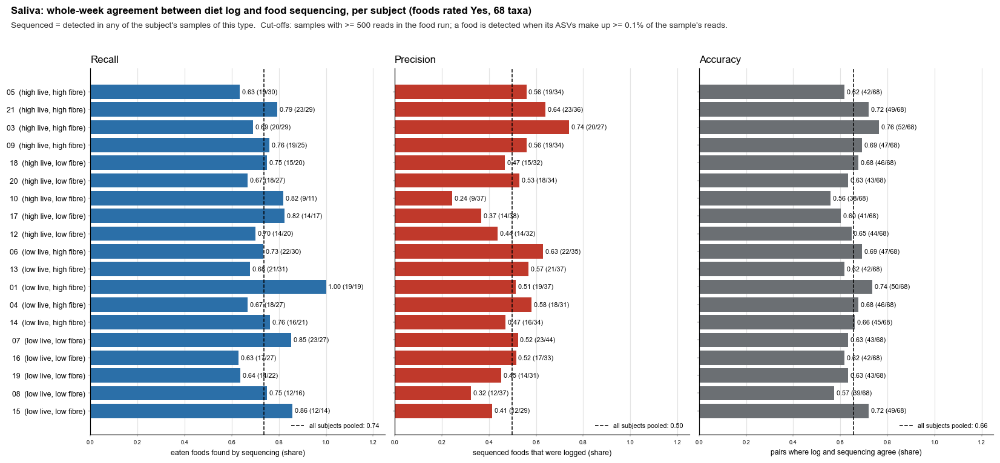

saved: 09_saliva_recall_precision_accuracy.png, 09_saliva_recall_precision_accuracy.pdf, 09_saliva_recall_precision_accuracy.csv


In [16]:
METRIC_COLORS = {"recall": "#2B6FA8", "precision": "#C0392B", "accuracy": "#6B6F73"}
_, per_subject_m, pooled = results["yes"]
order = list(grp.index)[::-1]                        # diet-group order, top to bottom
for label in SAMPLE_TYPES:
    d = per_subject_m[per_subject_m.sample_type == label].set_index("subject").reindex(order)
    fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
    for ax, m in zip(axes, ("recall", "precision", "accuracy")):
        ax.barh(d.index, d[m], color=METRIC_COLORS[m])
        num, den = {"recall": ("TP", ["TP", "FN"]), "precision": ("TP", ["TP", "FP"]), "accuracy": (None, None)}[m]
        for subj, r in d.iterrows():
            if pd.isna(r[m]):
                ax.text(0.01, subj, "n/a", va="center", fontsize=7)
                continue
            frac = f"{int(r[num])}/{int(sum(r[x] for x in den))}" if num else f"{int(r.TP + r.TN)}/{int(r.pairs)}"
            ax.text(r[m] + 0.01, subj, f"{r[m]:.2f} ({frac})", va="center", fontsize=7)
        ax.axvline(pooled.at[label, m], color="black", ls="--", lw=1, label=f"all subjects pooled: {pooled.at[label, m]:.2f}")
        ax.set_xlim(0, 1.25)
        ax.set_title(m.capitalize(), fontsize=11)
        ax.set_xlabel({"recall": "eaten foods found by sequencing", "precision": "sequenced foods that were logged",
                       "accuracy": "pairs where log and sequencing agree"}[m] + " (share)", fontsize=8)
        ax.legend(loc="lower right", fontsize=7, frameon=False)
        ax.grid(axis="x", color="#E3E3E3"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    axes[0].set_yticks(range(len(order)), [f"{s}  ({grp.at[s, 'group']})" for s in order], fontsize=8)
    extra = " (regions R1-R3 combined)" if label == "Capsule" else ""
    fig.suptitle(f"{label}{extra}: whole-week agreement between diet log and food sequencing, per subject "
                 f"(foods rated Yes, 68 taxa)", x=0.01, ha="left", fontweight="bold", fontsize=11)
    fig.text(0.01, 0.935, "Sequenced = detected in any of the subject's samples of this type.  " + cutoffs(), fontsize=9,
             color="#333333")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    files = DL.save(fig, f"09_{label.lower()}_recall_precision_accuracy", d.reset_index(), FIG_FOLDER)
    plt.show()
    print("saved:", ", ".join(f.name for f in files))

**How to read it:** one row per subject (grouped by diet group, 0.5), one panel per measure. The label gives the value and the
counts it is made of: recall "TP / (TP + FN)", precision "TP / (TP + FP)", accuracy "(TP + TN) / pairs". The dashed line is the
value for all subjects pooled (their confusion tables added together).

#### Comparing sample types (both definitions of "eaten")

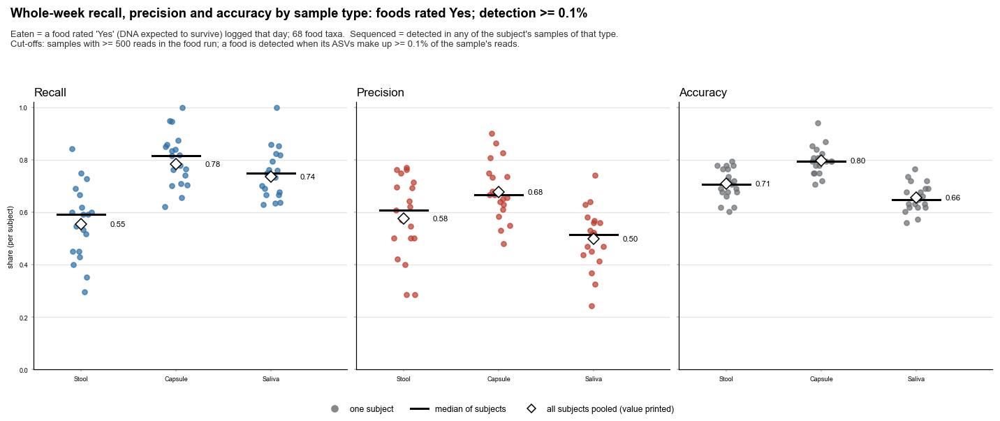

saved: 09_summary_by_sample_type_yes.png, 09_summary_by_sample_type_yes.pdf, 09_summary_by_sample_type_yes.csv


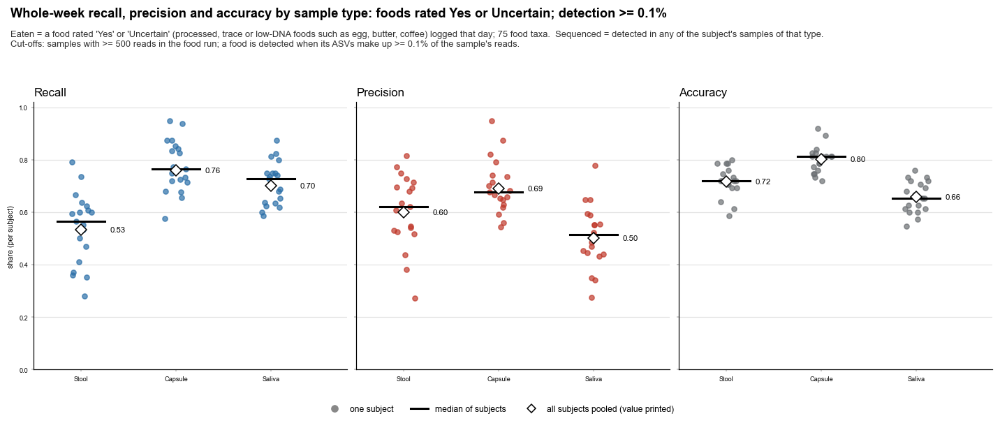

saved: 09_summary_by_sample_type_yes_uncertain.png, 09_summary_by_sample_type_yes_uncertain.pdf, 09_summary_by_sample_type_yes_uncertain.csv


In [17]:
def plot_summary(key, thr=DETECT_MIN, res=None, name=None, rule=None, method=None):
    # rule: replaces "detection >= x%" in the title; method: replaces the cut-off line (may have several lines)
    v = VERSIONS[key]
    _, per_subject_m, pooled = (res or results)[key]
    n_lines = 2 + (method.count("\n") if method else 0)
    fig, axes = plt.subplots(1, 3, figsize=(13, 5 + 0.2 * n_lines), sharey=True)
    rng = np.random.default_rng(3)                   # fixed seed: horizontal jitter of the dots
    for ax, m in zip(axes, ("recall", "precision", "accuracy")):
        for i, label in enumerate(SAMPLE_TYPES):
            vals = per_subject_m.loc[per_subject_m.sample_type == label, m].dropna()
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, s=22, color=METRIC_COLORS[m], alpha=0.7, zorder=3)
            ax.plot([i - 0.25, i + 0.25], [vals.median()] * 2, color="black", lw=2, zorder=4)
            ax.plot(i, pooled.at[label, m], marker="D", color="white", mec="black", ms=7, zorder=5)
            ax.text(i + 0.3, pooled.at[label, m], f"{pooled.at[label, m]:.2f}", va="center", fontsize=7.5)
        ax.set_xticks(range(len(SAMPLE_TYPES)), list(SAMPLE_TYPES))
        ax.set_xlim(-0.5, len(SAMPLE_TYPES) - 0.2)
        ax.set_ylim(0, 1.02)
        ax.set_title(m.capitalize(), fontsize=11)
        ax.grid(axis="y", color="#E3E3E3"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    axes[0].set_ylabel("share (per subject)")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color="#888888", label="one subject"),
                        Line2D([], [], color="black", lw=2, label="median of subjects"),
                        Line2D([], [], marker="D", ls="", mfc="white", mec="black", label="all subjects pooled (value printed)")],
               loc="lower center", ncol=3, frameon=False, fontsize=8)
    fig.suptitle(f"Whole-week recall, precision and accuracy by sample type: {v['title']}; " + (rule or f"detection >= {pct(thr)}"), x=0.01, y=0.99, ha="left",
                 fontweight="bold", fontsize=12)
    fig.text(0.01, 0.935, v["note"] + "  Sequenced = detected in any of the subject's samples of that type.\n" + (method or cutoffs(thr)),
             ha="left", va="top", fontsize=8.5, color="#333333")
    fig.tight_layout(rect=(0, 0.07, 1, 0.93 - 0.035 * n_lines))
    files = DL.save(fig, name or f"09_summary_by_sample_type_{key}", per_subject_m, FIG_FOLDER)
    plt.show()
    print("saved:", ", ".join(f.name for f in files))

for key in VERSIONS:
    plot_summary(key)

**How to read it:** each dot is one subject; the black bar is the median of the subjects and the white diamond (value printed)
the pooled value. Higher recall means more of the logged foods are found; higher precision means fewer foods are found that
were not logged. Comparing the two versions: counting `Uncertain` foods as eaten turns some "found but not logged" pairs into
true positives (precision up) and adds eaten foods whose DNA is often not found (recall may fall). Differences between sample
types and versions are descriptive here; they are tested in the analysis plan.

### 0.10 Stricter detection thresholds: 1% and 5% of reads
Sections 0.8 and 0.9 call a food taxon detected when its ASVs make up at least 0.1% of a sample's reads. A low threshold
catches small amounts of food DNA, but also traces from contamination or carry-over (plant DNA is found in the blanks, 0.3).
Here the same two summaries are redrawn with a food counted as detected only at **>= 1%** (the planned sensitivity analysis)
and **>= 5%** (exploratory, added at the user's request) of reads. Everything else is unchanged: same libraries (>= 500
reads), same food taxa, same two definitions of "eaten".

**Expected:** a stricter threshold can only remove detections, never add them. So recall can only fall or stay the same,
and the number of "found" pairs (TP + FP) can only shrink; precision rises if the removed detections were mostly
not-logged foods (background), and falls if they were mostly logged foods. The code checks the first two.

In [18]:
results_by_thr = {DETECT_MIN: results}               # 0.1%: computed in 0.9
for thr in DETECT_SENS:
    results_by_thr[thr] = {}
    for key, v in VERSIONS.items():
        pairs = confusion(v, thr)
        per_subject_m = pairs.groupby(["sample_type", "subject"]).apply(metrics, include_groups=False).reset_index()
        pooled = pairs.groupby("sample_type").apply(metrics, include_groups=False).reindex(list(SAMPLE_TYPES))
        results_by_thr[thr][key] = (pairs, per_subject_m, pooled)

# checks: same pairs at every threshold; a stricter threshold never adds a detection
for key in VERSIONS:
    base = results[key][0].set_index(["sample_type", "subject", "taxon_id"]).sequenced
    for thr in DETECT_SENS:
        strict = results_by_thr[thr][key][0].set_index(["sample_type", "subject", "taxon_id"]).sequenced
        same_pairs = base.index.equals(strict.index)
        print(f"check ({key}, >= {pct(thr)}): same pairs as at 0.1%: {same_pairs}; "
              f"detections added by the stricter threshold: {int((strict & ~base.reindex(strict.index)).sum())} (expected 0)")

# pooled values at each threshold, one table per definition of "eaten"
rows = [{"version": key, "threshold": pct(thr), "sample_type": label, **res[key][2].loc[label].to_dict()}
        for thr, res in results_by_thr.items() for key in VERSIONS for label in SAMPLE_TYPES]
by_thr = pd.DataFrame(rows)
for key in VERSIONS:
    print()
    print(f"all subjects pooled, version '{key}':")
    print(by_thr[by_thr.version == key].drop(columns="version").set_index(["sample_type", "threshold"])
          [["TP", "FN", "FP", "TN", "recall", "precision", "accuracy"]].round(3).to_string())

check (yes, >= 1%): same pairs as at 0.1%: True; detections added by the stricter threshold: 0 (expected 0)
check (yes, >= 5%): same pairs as at 0.1%: True; detections added by the stricter threshold: 0 (expected 0)
check (yes_uncertain, >= 1%): same pairs as at 0.1%: True; detections added by the stricter threshold: 0 (expected 0)
check (yes_uncertain, >= 5%): same pairs as at 0.1%: True; detections added by the stricter threshold: 0 (expected 0)

all subjects pooled, version 'yes':
                          TP     FN     FP     TN  recall  precision  accuracy
sample_type threshold                                                         
Stool       0.1%       245.0  197.0  180.0  670.0   0.554      0.576     0.708
Capsule     0.1%       346.0   96.0  165.0  685.0   0.783      0.677     0.798
Saliva      0.1%       325.0  117.0  327.0  523.0   0.735      0.498     0.656
Stool       1%         185.0  257.0  116.0  734.0   0.419      0.615     0.711
Capsule     1%         295.0  147.0  

#### Overview: how the values change with the threshold
One value per subject (their whole-week recall, precision or accuracy, as in 0.9), summarised across subjects at each
threshold: the dot is the **median of subjects**, the thick bar the **interquartile range** (middle half of subjects, 25th to
75th percentile) and the thin line the **range** (lowest to highest subject). The hollow diamond is the pooled value (all
subjects' counts added together), the number used in the 0.9 tables. Sample types are drawn side by side at each threshold.
Subjects with no eaten or no found food have no recall or precision and are left out of that summary (n printed below).

subjects per summary (min-max over thresholds, versions, measures): {'Capsule': {'min': 19, 'max': 19}, 'Saliva': {'min': 19, 'max': 19}, 'Stool': {'min': 19, 'max': 19}}


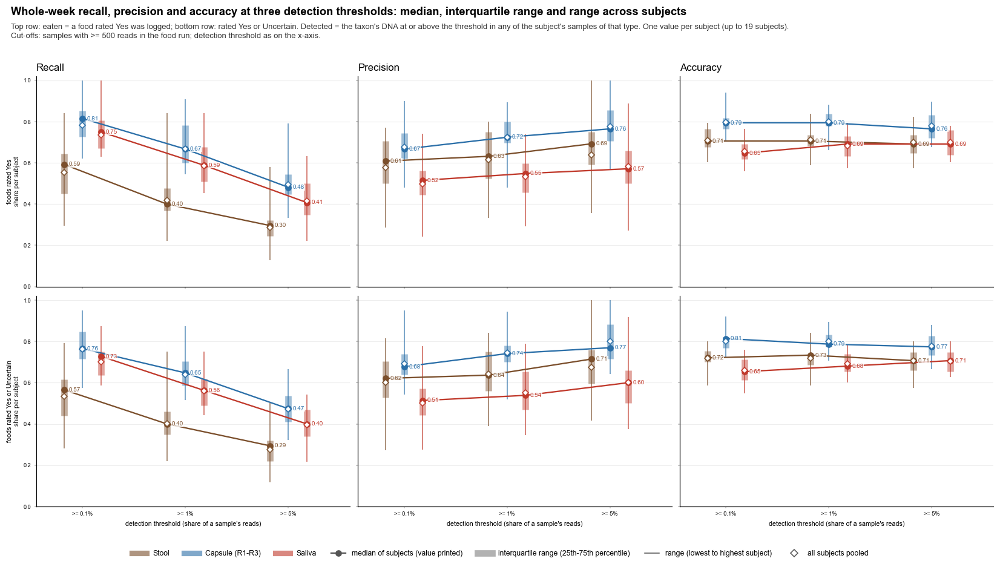

saved: 10_threshold_comparison.png, 10_threshold_comparison.pdf, 10_threshold_comparison.csv


In [19]:
# per-subject values at each threshold -> median, quartiles and range across subjects
srows = []
for thr, res in results_by_thr.items():
    for key in VERSIONS:
        ps, pooled = res[key][1], res[key][2]
        for label in SAMPLE_TYPES:
            for m in ("recall", "precision", "accuracy"):
                vals = ps.loc[ps.sample_type == label, m].dropna()
                srows.append({"version": key, "threshold": pct(thr), "sample_type": label, "measure": m, "n_subjects": len(vals),
                              "min": vals.min(), "q25": vals.quantile(0.25), "median": vals.median(),
                              "q75": vals.quantile(0.75), "max": vals.max(), "pooled": pooled.at[label, m]})
spread = pd.DataFrame(srows)
print("subjects per summary (min-max over thresholds, versions, measures):",
      spread.groupby("sample_type").n_subjects.agg(["min", "max"]).to_dict("index"))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True, sharey=True)
x = np.arange(len(results_by_thr))
TYPE_COLORS = {"Stool": "#7B4F2C", "Capsule": "#2B6FA8", "Saliva": "#C0392B"}
OFFSET = {"Stool": -0.18, "Capsule": 0.0, "Saliva": 0.18}         # side by side at each threshold
for row, key in enumerate(VERSIONS):
    for col, m in enumerate(("recall", "precision", "accuracy")):
        ax = axes[row, col]
        for label in SAMPLE_TYPES:
            d = spread[(spread.version == key) & (spread.sample_type == label) & (spread.measure == m)]
            xs, c = x + OFFSET[label], TYPE_COLORS[label]
            ax.vlines(xs, d["min"], d["max"], color=c, lw=1, alpha=0.8, zorder=2)            # range
            ax.vlines(xs, d.q25, d.q75, color=c, lw=7, alpha=0.45, zorder=3)                  # interquartile range
            ax.plot(xs, d["median"], "-o", color=c, lw=1.5, ms=6, zorder=4)                  # median of subjects
            ax.plot(xs, d.pooled, "D", mfc="white", mec=c, ms=5, zorder=5)                   # pooled
            for xi, val in zip(xs, d["median"]):
                ax.annotate(f"{val:.2f}", (xi, val), xytext=(5, 0), textcoords="offset points", fontsize=6.5, va="center",
                            color=c, bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.8), zorder=6)
        ax.set_xticks(x, [">= " + pct(t) for t in results_by_thr])
        ax.set_ylim(0, 1.02); ax.set_xlim(-0.45, len(x) - 0.4)
        ax.grid(axis="y", color="#EEEEEE"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        if row == 0:
            ax.set_title(m.capitalize(), fontsize=11)
        if row == 1:
            ax.set_xlabel("detection threshold (share of a sample's reads)")
    axes[row, 0].set_ylabel(f"{VERSIONS[key]['title']}\nshare per subject")
handles = [Line2D([], [], color=TYPE_COLORS[l], lw=6, alpha=0.6, label=l + (" (R1-R3)" if l == "Capsule" else ""))
           for l in SAMPLE_TYPES]
handles += [Line2D([], [], marker="o", ls="-", color="#555555", label="median of subjects (value printed)"),
            Line2D([], [], color="#555555", lw=7, alpha=0.45, label="interquartile range (25th-75th percentile)"),
            Line2D([], [], color="#555555", lw=1, label="range (lowest to highest subject)"),
            Line2D([], [], marker="D", ls="", mfc="white", mec="#555555", label="all subjects pooled")]
fig.legend(handles=handles, loc="lower center", ncol=7, frameon=False, fontsize=8)
fig.suptitle("Whole-week recall, precision and accuracy at three detection thresholds: median, interquartile range and range "
             "across subjects", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.95, "Top row: eaten = a food rated Yes was logged; bottom row: rated Yes or Uncertain. "
         "Detected = the taxon's DNA at or above the threshold in any of the subject's samples of that type. "
         "One value per subject (up to 19 subjects).\n" + f"Cut-offs: samples with >= {MIN_READS} reads in the food run; "
         "detection threshold as on the x-axis.", fontsize=8.5, color="#333333", va="top")
fig.tight_layout(rect=(0, 0.05, 1, 0.92))
files = DL.save(fig, "10_threshold_comparison", spread, FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** at each threshold the three sample types sit side by side (stool left, capsule middle, saliva right).
Follow one colour from left to right: a falling median in the recall panel means subjects' logged foods are lost at the
stricter threshold; a rising median in the precision panel means the removed detections were mostly foods that were not
logged. A long thin line or a wide thick bar means subjects differ a lot. Where the diamond sits away from the dot, the
pooled value is pulled by subjects with many pairs.

#### Figures 0.8 and 0.9 redrawn at 1% and at 5%
Same layout and reading as in 0.8 and 0.9; only the detection threshold differs (in the title and file name).

Threshold >= 1%, version 'yes' (foods rated Yes):
  Stool: pairs 1292; Spearman 0.37; average found share by regularity: never 0.03, <= 25% 0.11, 25-50% 0.19, 50-75% 0.25, > 75% 0.24
  Capsule: pairs 1292; Spearman 0.61; average found share by regularity: never 0.04, <= 25% 0.20, 25-50% 0.38, 50-75% 0.43, > 75% 0.65
  Saliva: pairs 1292; Spearman 0.39; average found share by regularity: never 0.08, <= 25% 0.16, 25-50% 0.25, 50-75% 0.32, > 75% 0.45


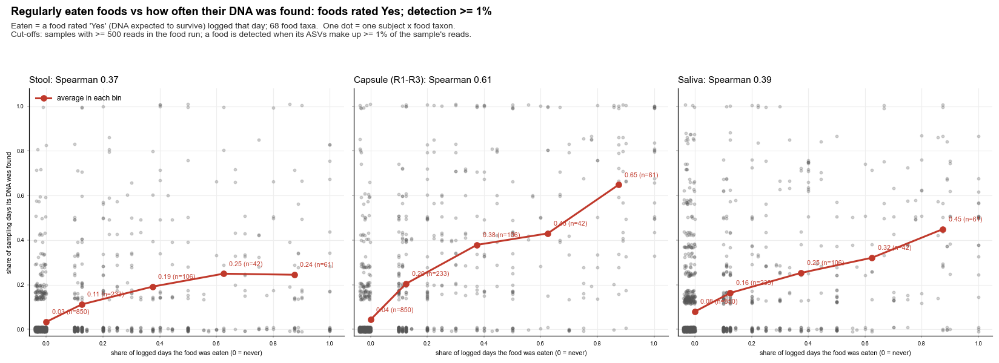

  saved: 10_regularity_vs_detection_yes_detect1pct.png, 10_regularity_vs_detection_yes_detect1pct.pdf, 10_regularity_vs_detection_yes_detect1pct.csv


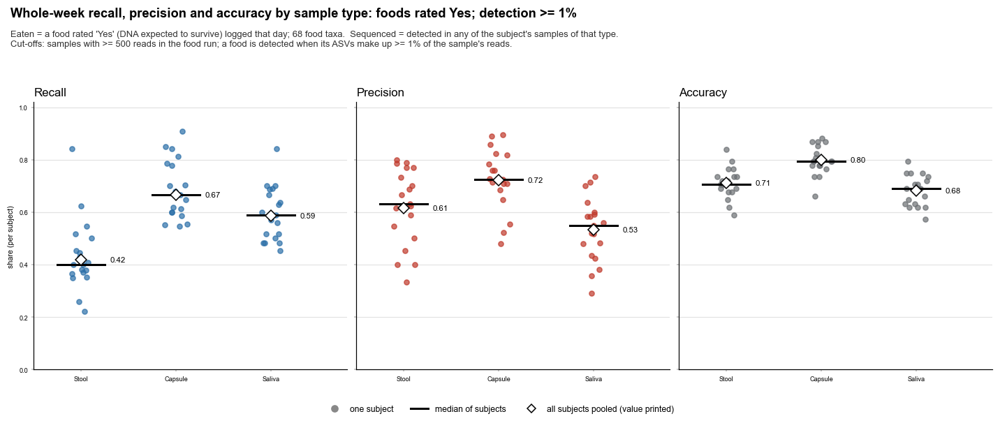

saved: 10_summary_by_sample_type_yes_detect1pct.png, 10_summary_by_sample_type_yes_detect1pct.pdf, 10_summary_by_sample_type_yes_detect1pct.csv
Threshold >= 1%, version 'yes_uncertain' (foods rated Yes or Uncertain):
  Stool: pairs 1425; Spearman 0.39; average found share by regularity: never 0.03, <= 25% 0.09, 25-50% 0.14, 50-75% 0.28, > 75% 0.29
  Capsule: pairs 1425; Spearman 0.62; average found share by regularity: never 0.03, <= 25% 0.17, 25-50% 0.30, 50-75% 0.50, > 75% 0.64
  Saliva: pairs 1425; Spearman 0.40; average found share by regularity: never 0.07, <= 25% 0.14, 25-50% 0.16, 50-75% 0.35, > 75% 0.50


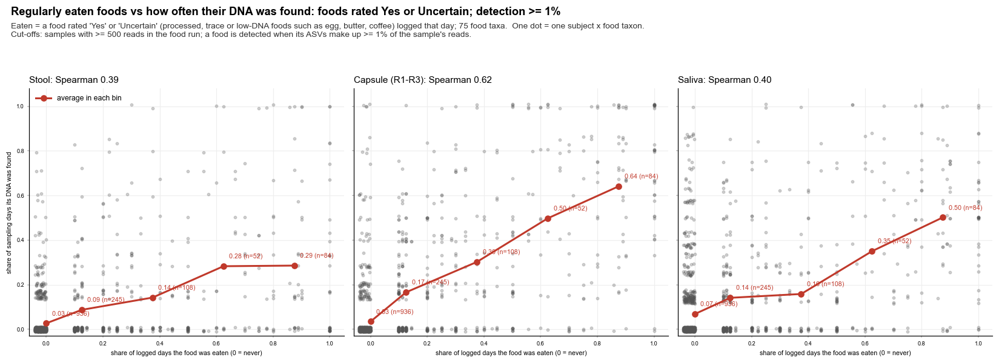

  saved: 10_regularity_vs_detection_yes_uncertain_detect1pct.png, 10_regularity_vs_detection_yes_uncertain_detect1pct.pdf, 10_regularity_vs_detection_yes_uncertain_detect1pct.csv


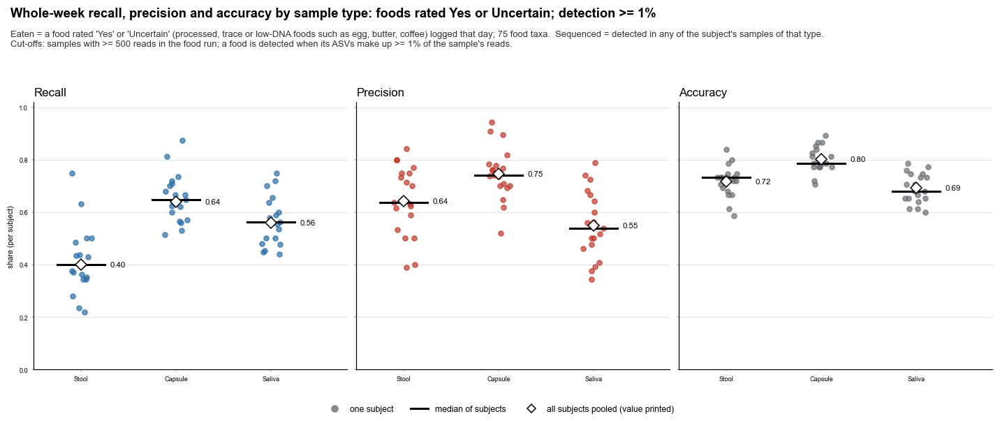

saved: 10_summary_by_sample_type_yes_uncertain_detect1pct.png, 10_summary_by_sample_type_yes_uncertain_detect1pct.pdf, 10_summary_by_sample_type_yes_uncertain_detect1pct.csv
Threshold >= 5%, version 'yes' (foods rated Yes):
  Stool: pairs 1292; Spearman 0.31; average found share by regularity: never 0.02, <= 25% 0.07, 25-50% 0.12, 50-75% 0.13, > 75% 0.16
  Capsule: pairs 1292; Spearman 0.54; average found share by regularity: never 0.02, <= 25% 0.10, 25-50% 0.23, 50-75% 0.26, > 75% 0.39
  Saliva: pairs 1292; Spearman 0.33; average found share by regularity: never 0.04, <= 25% 0.08, 25-50% 0.13, 50-75% 0.17, > 75% 0.20


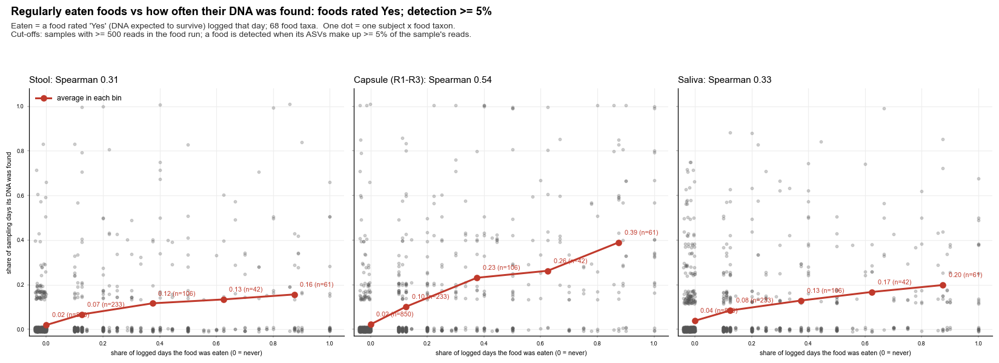

  saved: 10_regularity_vs_detection_yes_detect5pct.png, 10_regularity_vs_detection_yes_detect5pct.pdf, 10_regularity_vs_detection_yes_detect5pct.csv


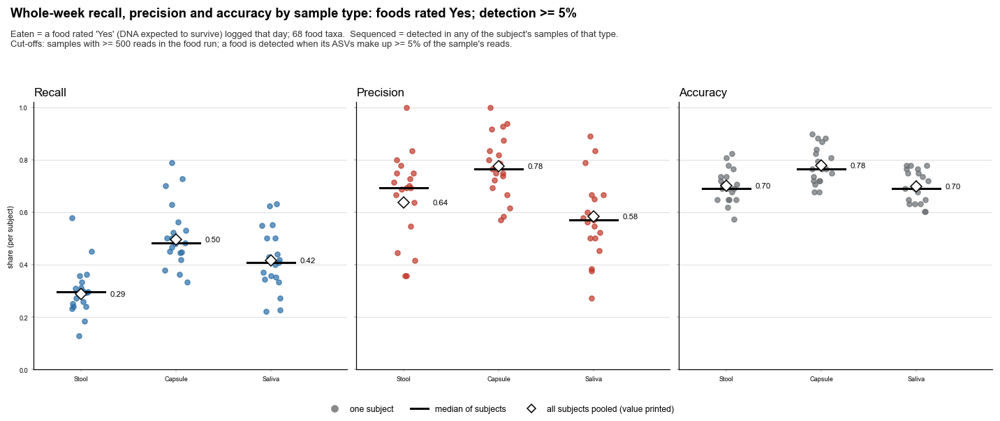

saved: 10_summary_by_sample_type_yes_detect5pct.png, 10_summary_by_sample_type_yes_detect5pct.pdf, 10_summary_by_sample_type_yes_detect5pct.csv
Threshold >= 5%, version 'yes_uncertain' (foods rated Yes or Uncertain):
  Stool: pairs 1425; Spearman 0.33; average found share by regularity: never 0.02, <= 25% 0.05, 25-50% 0.09, 50-75% 0.17, > 75% 0.18
  Capsule: pairs 1425; Spearman 0.55; average found share by regularity: never 0.02, <= 25% 0.08, 25-50% 0.16, 50-75% 0.30, > 75% 0.43
  Saliva: pairs 1425; Spearman 0.34; average found share by regularity: never 0.03, <= 25% 0.07, 25-50% 0.08, 50-75% 0.18, > 75% 0.25


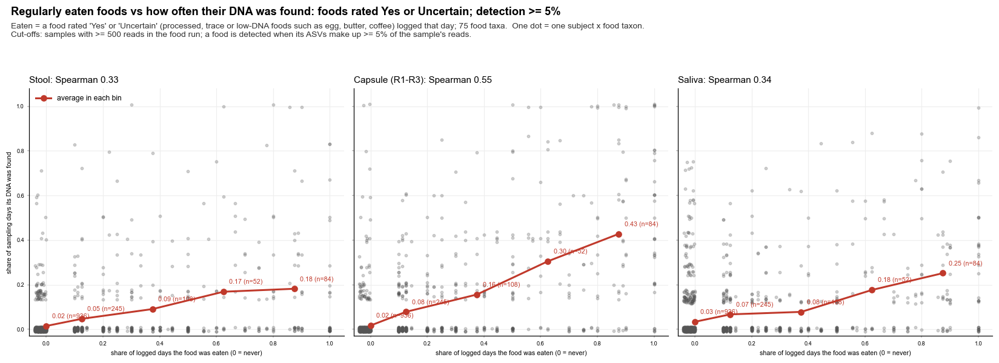

  saved: 10_regularity_vs_detection_yes_uncertain_detect5pct.png, 10_regularity_vs_detection_yes_uncertain_detect5pct.pdf, 10_regularity_vs_detection_yes_uncertain_detect5pct.csv


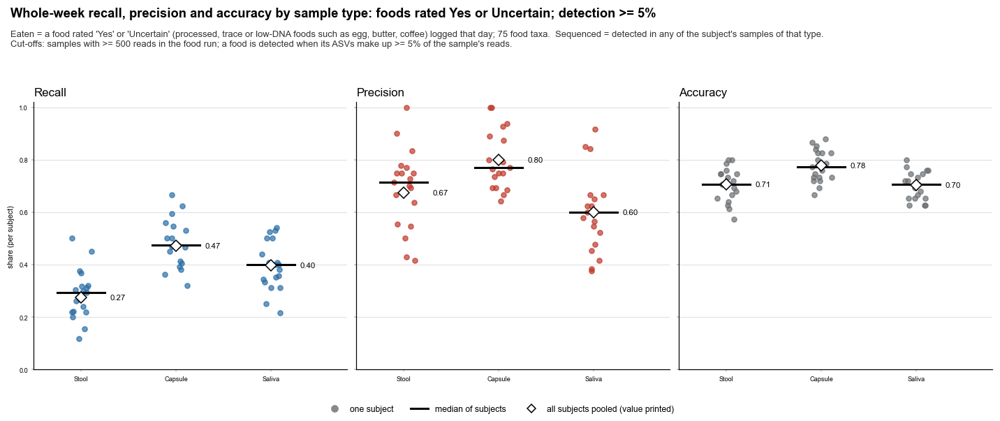

saved: 10_summary_by_sample_type_yes_uncertain_detect5pct.png, 10_summary_by_sample_type_yes_uncertain_detect5pct.pdf, 10_summary_by_sample_type_yes_uncertain_detect5pct.csv


In [20]:
for thr in DETECT_SENS:
    tag = f"detect{thr * 100:g}pct"
    for key, v in VERSIONS.items():
        v_thr = {**v, "det": v["det"].assign(detected=v["det"].max_rel >= thr)}   # day-level detection at this threshold
        print(f"Threshold >= {pct(thr)}, version '{key}' ({v['title']}):")
        plot_regularity(regularity_table(v_thr), v_thr, f"10_regularity_vs_detection_{key}_{tag}", thr)
        plot_summary(key, thr, results_by_thr[thr], f"10_summary_by_sample_type_{key}_{tag}")

### 0.11 How many reads lie behind each detection?
For every detection at the primary rule (food taxon >= 0.1% of a sample's reads, samples with >= 500 reads), the number of
reads of that food taxon in the sample. One count per subject x day x sample type x food taxon: if a day has several
libraries of one type (e.g. capsule regions R1-R3), the largest count is used. Foods rated Yes (68 taxa); libraries without
a collection date are left out (as in 0.4). One panel per run (rows) and sample type (columns); the x-axis is logarithmic
because counts range from a few reads to millions.

**Expected:** few detections rest on a handful of reads (otherwise single stray reads drive the results); the dashed line
marks `MIN_TAXON_READS` (10 reads), the extra requirement of sensitivity rule 1 in 0.12.

detections (subject x day x sample type x food taxon): 4,376


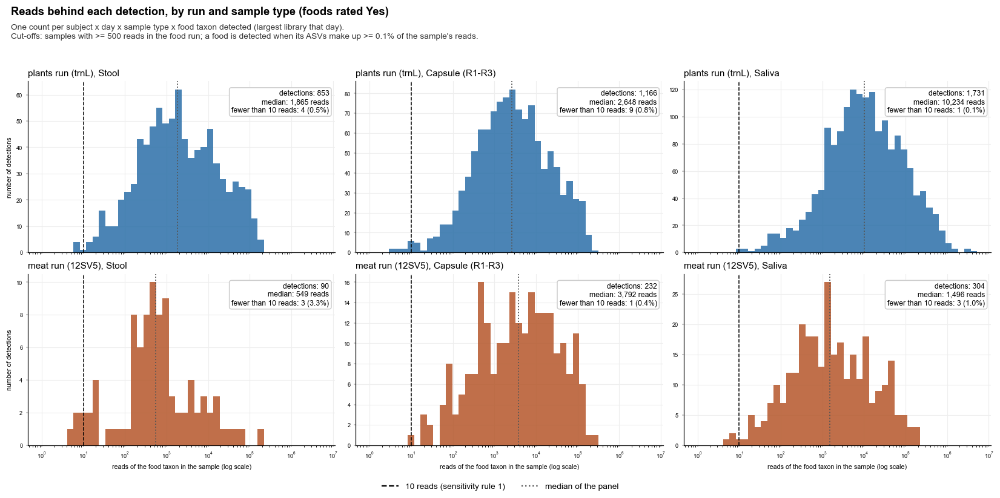

   run sample_type  detections  median_reads  under_10_reads
plants       Stool         853        1865.0               4
plants     Capsule        1166        2647.5               9
plants      Saliva        1731       10234.0               1
  meat       Stool          90         549.0               3
  meat     Capsule         232        3792.0               1
  meat      Saliva         304        1496.0               3
saved: 11_detection_reads_histogram.png, 11_detection_reads_histogram.pdf, 11_detection_reads_histogram.csv


In [21]:
# reads of the taxon in a library = its share x the library's reads (taxon_abundance divides by the same total)
ab_reads = ab.merge(lib[["run", "library", "reads"]], on=["run", "library"])
ab_reads["taxon_reads"] = (ab_reads.rel * ab_reads.reads).round().astype(int)
hit = ab_reads[ab_reads.rel >= DETECT_MIN]
hit_days = (hit.groupby(["run", "Sample_origin3", "Subject_ID", "date", "taxon_id"]).taxon_reads.max().reset_index())
print(f"detections (subject x day x sample type x food taxon): {len(hit_days):,}")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
bins = np.logspace(0, np.log10(hit_days.taxon_reads.max() * 1.1), 45)
rows_out = []
for i, run in enumerate(["plants", "meat"]):
    for j, (label, origin) in enumerate(SAMPLE_TYPES.items()):
        ax = axes[i, j]
        x = hit_days[(hit_days.run == run) & (hit_days.Sample_origin3 == origin)].taxon_reads
        ax.hist(x, bins=bins, color="#2B6FA8" if run == "plants" else "#B5562A", alpha=0.85)
        ax.set_xscale("log")
        ax.axvline(MIN_TAXON_READS, color="black", ls="--", lw=1)
        ax.axvline(x.median(), color="#555555", ls=":", lw=1.2)
        under = (x < MIN_TAXON_READS).sum()
        ax.text(0.98, 0.95, f"detections: {len(x):,}\nmedian: {x.median():,.0f} reads\n"
                f"fewer than {MIN_TAXON_READS} reads: {under} ({under / max(len(x), 1):.1%})",
                transform=ax.transAxes, ha="right", va="top", fontsize=8,
                bbox=dict(fc="white", ec="#CCCCCC", boxstyle="round,pad=0.3"))
        ax.set_title(f"{run} run ({'trnL' if run == 'plants' else '12SV5'}), {label}" + (" (R1-R3)" if label == "Capsule" else ""),
                     fontsize=10, loc="left")
        if i == 1:
            ax.set_xlabel("reads of the food taxon in the sample (log scale)")
        if j == 0:
            ax.set_ylabel("number of detections")
        ax.grid(color="#EEEEEE"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        rows_out.append({"run": run, "sample_type": label, "detections": len(x), "median_reads": x.median(),
                         f"under_{MIN_TAXON_READS}_reads": int(under)})
fig.legend(handles=[Line2D([], [], color="black", ls="--", label=f"{MIN_TAXON_READS} reads (sensitivity rule 1)"),
                    Line2D([], [], color="#555555", ls=":", label="median of the panel")],
           loc="lower center", ncol=2, frameon=False, fontsize=9)
fig.suptitle("Reads behind each detection, by run and sample type (foods rated Yes)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, 0.945, "One count per subject x day x sample type x food taxon detected (largest library that day).\n"
         + cutoffs(), fontsize=9, color="#333333", va="top")
fig.tight_layout(rect=(0, 0.04, 1, 0.9))
files = DL.save(fig, "11_detection_reads_histogram", hit_days, FIG_FOLDER)
plt.show()
print(pd.DataFrame(rows_out).to_string(index=False))
print("saved:", ", ".join(f.name for f in files))

**How to read it:** each bar counts detections whose food taxon had that many reads in the sample. Bars left of the dashed
line are detections resting on fewer than 10 reads, the ones sensitivity rule 1 removes. Saliva in the plants run sits
furthest right because those libraries are sequenced most deeply (0.3).

### 0.12 Sensitivity analyses for the whole-week summary (0.9)
The whole-week recall, precision and accuracy of 0.9 are recomputed with three other rules for "detected". Everything else
is unchanged (same food taxa, same two definitions of "eaten", same pairs unless a rule removes libraries). Each figure
states its rule. Exploratory checks on the primary rule (>= 0.1% of reads in samples with >= 500 reads), not tests.

1. **Share and count.** Detected when the taxon makes up >= 0.1% of the sample's reads **and** has at least
   `MIN_TAXON_READS` (10) reads. Removes detections that rest on a few stray reads in shallow samples.
   **Expected:** almost no change (0.11 shows few such detections); never adds a detection.
2. **Rarefying (equal depth).** Each library is randomly subsampled, without replacement, to `RARE_DEPTH` (2,000) reads
   (fixed seed `RARE_SEED`); libraries with fewer reads are left out. Detected when the taxon has >= `RARE_MIN` (2) of the
   2,000 reads (= 0.1%). Every sample then has the same chance of catching a rare food, so deeply sequenced samples (plants
   saliva) are not favoured. **Expected:** recall falls, most in deep samples, because small amounts of DNA are lost in
   subsampling; can add a detection only by chance near the threshold.
3. **Blanks (contamination).** For each food taxon, its share of reads in every blank of the same run (blanks with >= 500
   reads) is computed; a sample counts as detected only if the taxon's share is >= 0.1% **and** above the taxon's 95th
   percentile in the blanks. Foods often seen in blanks need a higher share. **Expected:** precision rises if the blank
   DNA comes from foods that were not logged; never adds a detection.

In [22]:
RULES = {}          # rule key -> (title, method text for the figure, results per version)

# rule 1: share and count
RULES["rule1_min_reads"] = (
    f"rule 1, >= 0.1% and >= {MIN_TAXON_READS} reads",
    f"Rule 1 (share and count): detected when the food taxon makes up >= {pct(DETECT_MIN)} of the sample's reads AND has "
    f">= {MIN_TAXON_READS} reads in it.\nSamples with >= {MIN_READS} reads in the food run.",
    {key: confusion(v, detect=lambda a: (a.rel >= DETECT_MIN) & (a.rel * a.reads >= MIN_TAXON_READS - 0.5))
     for key, v in VERSIONS.items()})

# rule 2: rarefy every included library to RARE_DEPTH reads
rng = np.random.default_rng(RARE_SEED)
lib_rare = lib[lib.included & (lib.reads >= RARE_DEPTH)].copy()
runs_rare = {}
for run, (counts, tax) in runs.items():
    libs = lib_rare.loc[lib_rare.run == run, "library"]
    libs = libs[libs.isin(counts.index)]
    sub = counts.loc[libs].to_numpy().astype(np.int64)
    rare = np.vstack([rng.multivariate_hypergeometric(row, RARE_DEPTH) for row in sub])   # sampling without replacement
    runs_rare[run] = (pd.DataFrame(rare, index=libs.to_numpy(), columns=counts.columns), tax)
    print(f"rule 2, {run}: {len(libs)} libraries subsampled to {RARE_DEPTH:,} reads; "
          f"left out (fewer reads): {int((lib.included & (lib.run == run) & (lib.reads < RARE_DEPTH)).sum())}; "
          f"check every row sums to {RARE_DEPTH}: {bool((rare.sum(axis=1) == RARE_DEPTH).all())}")
lib_rare["reads"] = RARE_DEPTH
RULES["rule2_rarefied"] = (
    f"rule 2, rarefied to {RARE_DEPTH:,} reads",
    f"Rule 2 (rarefying): every sample randomly subsampled without replacement to {RARE_DEPTH:,} reads (seed {RARE_SEED}); "
    f"samples with fewer reads left out.\nDetected when the food taxon has >= {RARE_MIN} of the {RARE_DEPTH:,} reads "
    f"(= {pct(RARE_MIN / RARE_DEPTH)}).",
    {key: confusion(v, lib_used=lib_rare, runs_used=runs_rare, detect=lambda a: a.rel * RARE_DEPTH >= RARE_MIN - 0.5)
     for key, v in VERSIONS.items()})

# rule 3: above the taxon's level in the blanks of the same run
blank_lib = []
for run, (counts, _) in runs.items():
    bl = info[(info["group"] == FS.INFO_GROUP[run]) & (info["Group"] == "Blank")]["Sample"].str.replace("sample_", "", n=1)
    bl = bl[bl.isin(counts.index)]
    blank_lib.append(pd.DataFrame({"run": run, "library": bl.to_numpy(), "reads": counts.loc[bl].sum(axis=1).to_numpy()}))
blank_lib = pd.concat(blank_lib, ignore_index=True)
blank_lib = blank_lib[blank_lib.reads >= MIN_READS]
print("rule 3, blanks used (>= 500 reads):", blank_lib.groupby("run").size().to_dict())
res3 = {}
blank_cut = {}
for key, v in VERSIONS.items():
    bab = FS.taxon_abundance(blank_lib, v["taxa"], runs)
    cut = bab.groupby("taxon_id").rel.quantile(BLANK_QUANTILE)            # one cut-off per food taxon
    blank_cut[key] = cut
    res3[key] = confusion(v, detect=lambda a, cut=cut: (a.rel >= DETECT_MIN) & (a.rel > a.taxon_id.map(cut).fillna(0)))
    print(f"rule 3, version '{key}': taxa whose blank cut-off is above 0.1%: {int((cut > DETECT_MIN).sum())} of {len(cut)}")
    if key == "yes":
        high = cut[cut > DETECT_MIN].sort_values(ascending=False)
        print("  those taxa, with their blank cut-off (share of reads):",
              "; ".join(f"{v['label'][t]} {c:.2%}" for t, c in high.items()))
RULES["rule3_blanks"] = (
    f"rule 3, above the blanks",
    f"Rule 3 (blanks): for each food taxon, its share of reads in each blank of the same run (blanks with >= {MIN_READS} reads); "
    f"detected when the taxon makes up >= {pct(DETECT_MIN)} of the sample's reads\nAND more than its "
    f"{BLANK_QUANTILE:.0%} percentile in the blanks. Samples with >= {MIN_READS} reads in the food run.",
    res3)

# plain-language explanation of each rule, written on the figures (numbers come from the steps above)
import textwrap
n_left = {run: int((lib.included & (lib.run == run) & (lib.reads < RARE_DEPTH)).sum()) for run in runs}
n_blank = blank_lib.groupby("run").size().to_dict()
top_cut = blank_cut["yes"].sort_values(ascending=False).head(3)
top_cut_text = ", ".join(f"{VERSIONS['yes']['label'][t].split(' (')[0]} {c:.1%}" for t, c in top_cut.items())
RULE_TEXT = {
    "primary": (f"Primary rule: a food counts as detected in a sample when its DNA makes up at least {pct(DETECT_MIN)} of the "
                f"sample's reads (1 read in {1 / DETECT_MIN:,.0f}). Only samples with at least {MIN_READS} reads in the food run are used."),
    "rule1_min_reads": (f"Rule 1: as the primary rule, and the food must also have at least {MIN_TAXON_READS} reads in the sample, "
                        "so a few stray reads in a small sample cannot count as a detection."),
    "rule2_rarefied": (f"Rule 2: every sample is cut down at random to exactly {RARE_DEPTH:,} of its reads (seed {RARE_SEED}), so all "
                       f"samples are compared at the same sequencing depth; a food is detected if at least {RARE_MIN} of those "
                       f"{RARE_DEPTH:,} reads are its DNA. A sample that has fewer than {RARE_DEPTH:,} reads cannot be cut down to "
                       f"{RARE_DEPTH:,}, so it is not used: {n_left['plants']} plants-run and {n_left['meat']} meat-run samples."),
    "rule3_blanks": ("Rule 3: blanks are controls with no sample in them, so food DNA found in a blank is contamination. For each "
                     f"food, its share of reads was measured in every blank of the same run ({n_blank.get('plants', 0)} plants-run "
                     f"and {n_blank.get('meat', 0)} meat-run blanks with at least {MIN_READS} reads). The food's 'blank level' is "
                     f"the share that {BLANK_QUANTILE * 100:.0f} of every 100 blanks stay below (its {BLANK_QUANTILE * 100:.0f}th "
                     "percentile). A food counts as detected only if it passes the primary rule AND its share in the sample is "
                     "higher than its blank level. Most foods have a blank level below 0.1%, so nothing changes for them; a few "
                     f"have a high one ({top_cut_text}), so they are rarely detected under this rule."),
}
def wrapped(key, width):
    return "\n".join(textwrap.wrap(RULE_TEXT[key], width))
for rk in RULES:
    RULES[rk] = (RULES[rk][0], wrapped(rk, 190), RULES[rk][2])

# metrics per rule, and checks against the primary rule
results_by_rule = {"primary": results}
for rk, (_, _, pairs_by_v) in RULES.items():
    results_by_rule[rk] = {}
    for key, pairs in pairs_by_v.items():
        ps = pairs.groupby(["sample_type", "subject"]).apply(metrics, include_groups=False).reset_index()
        po = pairs.groupby("sample_type").apply(metrics, include_groups=False).reindex(list(SAMPLE_TYPES))
        results_by_rule[rk][key] = (pairs, ps, po)
        base = results[key][0].set_index(["sample_type", "subject", "taxon_id"]).sequenced
        new = pairs.set_index(["sample_type", "subject", "taxon_id"]).sequenced
        common = new.index.intersection(base.index)
        added = int((new.loc[common] & ~base.loc[common]).sum())
        print(f"check {rk}, '{key}': pairs {len(new)} (primary {len(base)}); detections added vs primary: {added}"
              + ("" if rk == "rule2_rarefied" else " (expected 0)"))

rule 2, plants: 600 libraries subsampled to 2,000 reads; left out (fewer reads): 2; check every row sums to 2000: True
rule 2, meat: 556 libraries subsampled to 2,000 reads; left out (fewer reads): 24; check every row sums to 2000: True
rule 3, blanks used (>= 500 reads): {'meat': 67, 'plants': 105}


rule 3, version 'yes': taxa whose blank cut-off is above 0.1%: 11 of 68
  those taxa, with their blank cut-off (share of reads): Glycine max (trnL) 98.79%; Sus scrofa (12SV5) 39.48%; Lactuca sativa (trnL) 2.15%; Bos taurus (12SV5) 1.56%; Triticum aestivum (trnL) 1.55%; Musa spp. (trnL) 1.54%; Brassica spp. (trnL) 1.37%; Gallus gallus (12SV5) 1.16%; Persea americana (trnL) 0.75%; Anacardium occidentale (trnL) 0.71%; Prunus spp. (trnL) 0.13%
rule 3, version 'yes_uncertain': taxa whose blank cut-off is above 0.1%: 11 of 75
check rule1_min_reads, 'yes': pairs 3876 (primary 3876); detections added vs primary: 0 (expected 0)
check rule1_min_reads, 'yes_uncertain': pairs 4275 (primary 4275); detections added vs primary: 0 (expected 0)
check rule2_rarefied, 'yes': pairs 3876 (primary 3876); detections added vs primary: 44
check rule2_rarefied, 'yes_uncertain': pairs 4275 (primary 4275); detections added vs primary: 52
check rule3_blanks, 'yes': pairs 3876 (primary 3876); detections added vs pr

check rule3_blanks, 'yes_uncertain': pairs 4275 (primary 4275); detections added vs primary: 0 (expected 0)


#### Figures: whole-week summary under each rule
Same layout and reading as the 0.9 summary; the rule and how it is applied are written under each title.

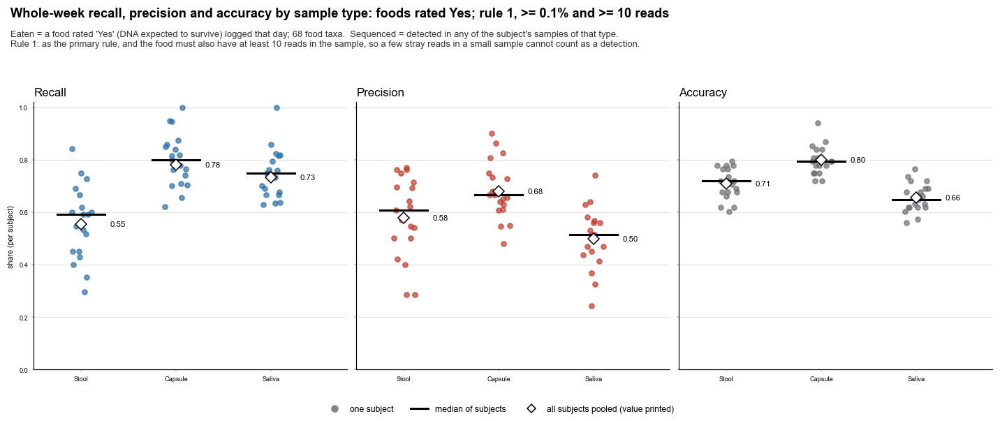

saved: 12_summary_by_sample_type_yes_rule1_min_reads.png, 12_summary_by_sample_type_yes_rule1_min_reads.pdf, 12_summary_by_sample_type_yes_rule1_min_reads.csv


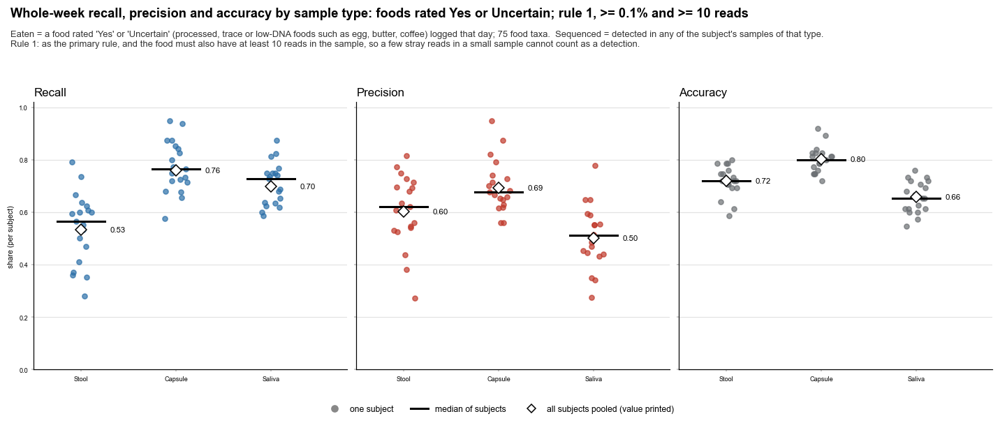

saved: 12_summary_by_sample_type_yes_uncertain_rule1_min_reads.png, 12_summary_by_sample_type_yes_uncertain_rule1_min_reads.pdf, 12_summary_by_sample_type_yes_uncertain_rule1_min_reads.csv


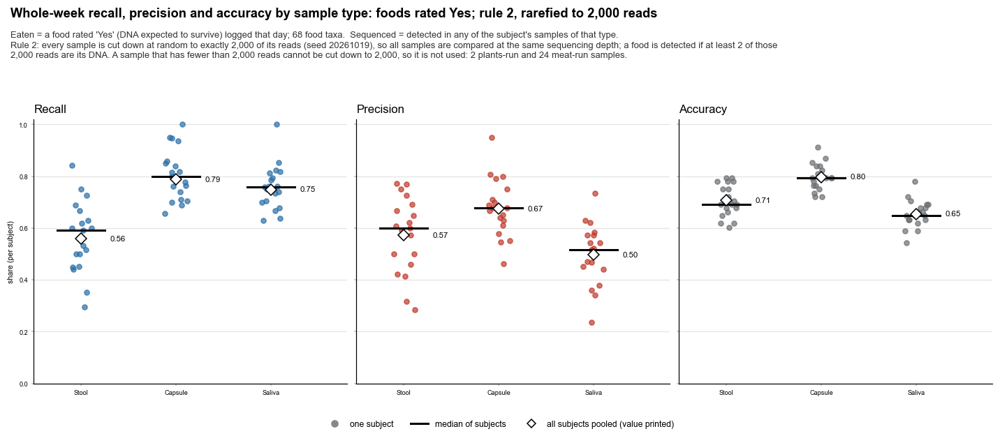

saved: 12_summary_by_sample_type_yes_rule2_rarefied.png, 12_summary_by_sample_type_yes_rule2_rarefied.pdf, 12_summary_by_sample_type_yes_rule2_rarefied.csv


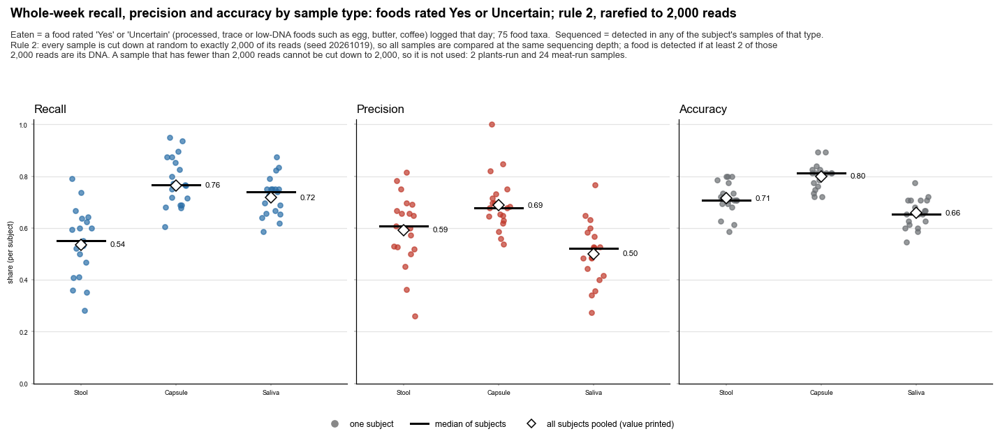

saved: 12_summary_by_sample_type_yes_uncertain_rule2_rarefied.png, 12_summary_by_sample_type_yes_uncertain_rule2_rarefied.pdf, 12_summary_by_sample_type_yes_uncertain_rule2_rarefied.csv


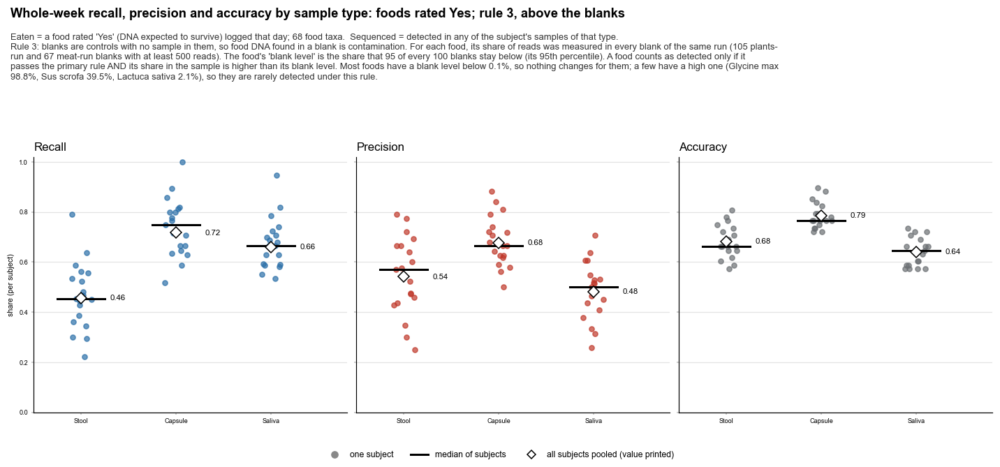

saved: 12_summary_by_sample_type_yes_rule3_blanks.png, 12_summary_by_sample_type_yes_rule3_blanks.pdf, 12_summary_by_sample_type_yes_rule3_blanks.csv


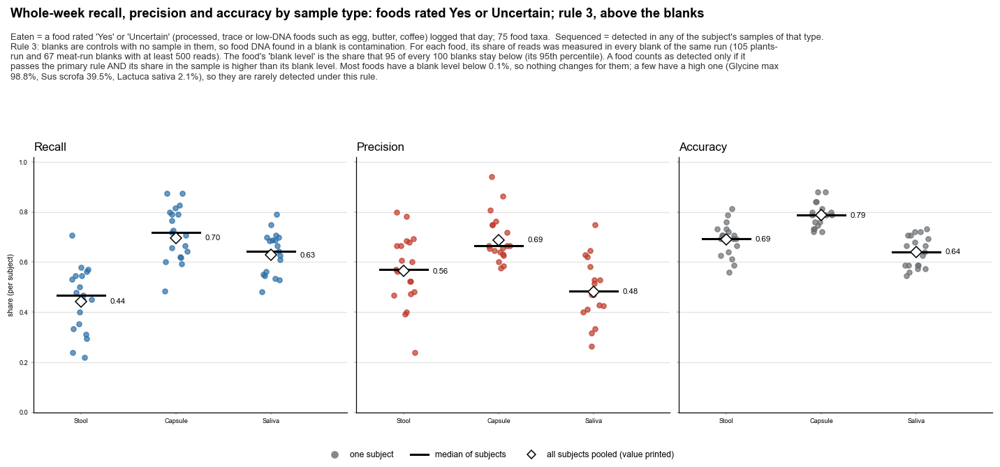

saved: 12_summary_by_sample_type_yes_uncertain_rule3_blanks.png, 12_summary_by_sample_type_yes_uncertain_rule3_blanks.pdf, 12_summary_by_sample_type_yes_uncertain_rule3_blanks.csv


In [23]:
for rk, (title, method, _) in RULES.items():
    for key in VERSIONS:
        plot_summary(key, res=results_by_rule[rk], name=f"12_summary_by_sample_type_{key}_{rk}", rule=title, method=method)

#### Overview: the primary rule next to the three sensitivity rules

subjects per summary: sample_type      Capsule  Saliva  Stool
rule                                   
primary               19      19     19
rule1_min_reads       19      19     19
rule2_rarefied        19      19     19
rule3_blanks          19      19     19


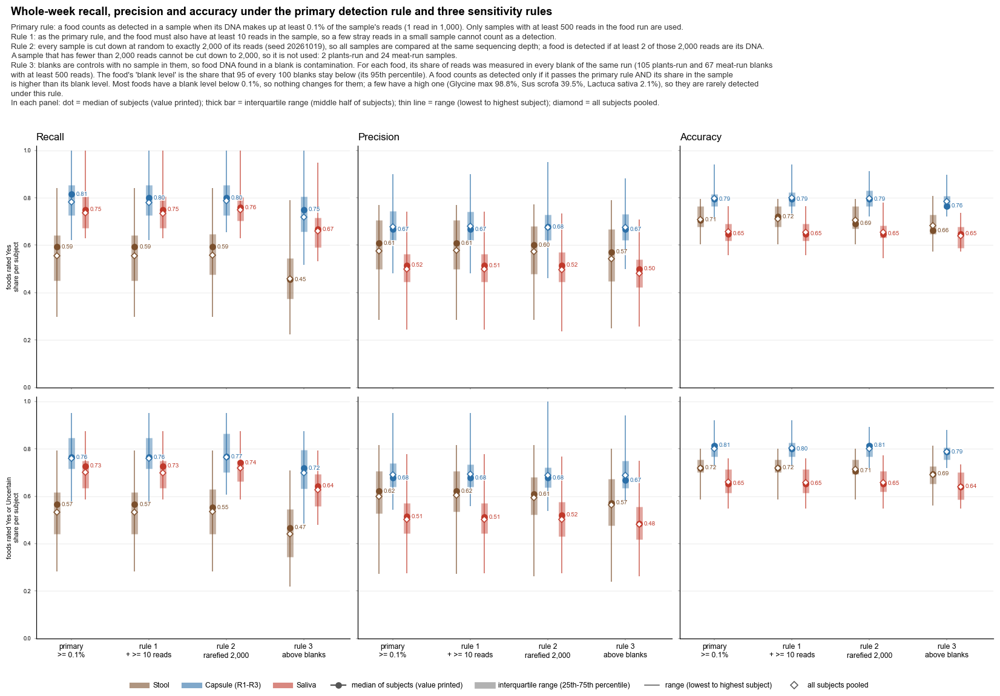

saved: 12_sensitivity_comparison.png, 12_sensitivity_comparison.pdf, 12_sensitivity_comparison.csv


In [24]:
RULE_LABELS = {"primary": "primary\n>= 0.1%", "rule1_min_reads": f"rule 1\n+ >= {MIN_TAXON_READS} reads",
               "rule2_rarefied": f"rule 2\nrarefied {RARE_DEPTH:,}", "rule3_blanks": "rule 3\nabove blanks"}
srows = []
for rk, res in results_by_rule.items():
    for key in VERSIONS:
        ps, po = res[key][1], res[key][2]
        for label in SAMPLE_TYPES:
            for m in ("recall", "precision", "accuracy"):
                vals = ps.loc[ps.sample_type == label, m].dropna()
                srows.append({"rule": rk, "version": key, "sample_type": label, "measure": m, "n_subjects": len(vals),
                              "min": vals.min(), "q25": vals.quantile(0.25), "median": vals.median(),
                              "q75": vals.quantile(0.75), "max": vals.max(), "pooled": po.at[label, m]})
spread_rules = pd.DataFrame(srows)
print("subjects per summary:", spread_rules.groupby(["rule", "sample_type"]).n_subjects.min().unstack().to_string())

caption = "\n".join(wrapped(k, 215) for k in RULE_TEXT) + ("\nIn each panel: dot = median of subjects (value printed); "
           "thick bar = interquartile range (middle half of subjects); thin line = range (lowest to highest subject); "
           "diamond = all subjects pooled.")
n_cap = caption.count("\n") + 1
fig, axes = plt.subplots(2, 3, figsize=(15, 9 + 0.17 * n_cap), sharex=True, sharey=True)
x = np.arange(len(RULE_LABELS))
for row, key in enumerate(VERSIONS):
    for col, m in enumerate(("recall", "precision", "accuracy")):
        ax = axes[row, col]
        for label in SAMPLE_TYPES:
            d = spread_rules[(spread_rules.version == key) & (spread_rules.sample_type == label) & (spread_rules.measure == m)]
            d = d.set_index("rule").reindex(list(RULE_LABELS))
            xs, c = x + OFFSET[label], TYPE_COLORS[label]
            ax.vlines(xs, d["min"], d["max"], color=c, lw=1, alpha=0.8, zorder=2)
            ax.vlines(xs, d.q25, d.q75, color=c, lw=7, alpha=0.45, zorder=3)
            ax.plot(xs, d["median"], "o", color=c, ms=6, zorder=4)
            ax.plot(xs, d.pooled, "D", mfc="white", mec=c, ms=5, zorder=5)
            for xi, val in zip(xs, d["median"]):
                ax.annotate(f"{val:.2f}", (xi, val), xytext=(5, 0), textcoords="offset points", fontsize=6.5, va="center",
                            color=c, bbox=dict(boxstyle="square,pad=0.05", fc="white", ec="none", alpha=0.8), zorder=6)
        ax.set_xticks(x, list(RULE_LABELS.values()), fontsize=8)
        ax.set_ylim(0, 1.02); ax.set_xlim(-0.45, len(x) - 0.4)
        ax.grid(axis="y", color="#EEEEEE"); ax.set_axisbelow(True)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        if row == 0:
            ax.set_title(m.capitalize(), fontsize=11)
    axes[row, 0].set_ylabel(f"{VERSIONS[key]['title']}\nshare per subject")
fig.legend(handles=handles, loc="lower center", ncol=7, frameon=False, fontsize=8)
fig.suptitle("Whole-week recall, precision and accuracy under the primary detection rule and three sensitivity rules",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.955, caption, fontsize=8.5, color="#333333", va="top", linespacing=1.35)
fig.tight_layout(rect=(0, 0.04, 1, 0.945 - 0.0125 * n_cap))
files = DL.save(fig, "12_sensitivity_comparison", spread_rules, FIG_FOLDER)
plt.show()
print("saved:", ", ".join(f.name for f in files))

**How to read it:** at each rule the three sample types sit side by side (stool, capsule, saliva). Compare each rule with
the primary rule on the left: a rule that leaves the medians where they are means the 0.9 results do not depend on that
choice; a rule that moves them shows what the primary rule is sensitive to (stray reads: rule 1; sequencing depth: rule 2;
contamination: rule 3).

# 1. Analysis plan (component 1)

*To be drafted next.* Decided so far (2026-10-19; see `PROGRESS.md`): "recall" and "precision" are the measures
(no specificity); the time-since-eaten curve is primary, with recall and precision at 12 h-5 d labelled as chosen from an
earlier look at these data; detection at >= 0.1% of a library's reads (1% as sensitivity analysis) in libraries with >= 500
reads; stool first, then capsules, then saliva.